# 2-motor: no-load-current

Measure the current the free motor draws against its speed, the drag that current stands for, and the rotor's inertia, from the spins and coasts of the bemf-coast dataset.

## Purpose

A motor turning with nothing on its shaft still draws current. That current is the torque the motor spends on its own drag, the brushes on the commutator, the bearings, the air around the rotor and the iron loss in the rotor's core, divided by the torque constant. Every current the servo reads under motion carries it, so a stall detector, a load estimate or a torque command that does not know the no-load current reads the motor's own drag as load. The no-load current rises with speed, and the shape of the rise says what kind of drag it is.

This experiment reads it off the spins of the bemf-coast dataset, where the free motor is driven at a set duty for a second and a half and then let go. The end of each spin gives the current at a settled speed. The coast that follows gives the drag a second way, as the rate the rotor slows at, with the speed counted in the ripple of the coasting voltage. The two are tied by the rotor's inertia. At a steady speed the drive's torque equals the drag, and in the coast the drag alone slows the rotor, so if the drag is the same in both, one inertia turns the coast's deceleration into the spin's current at every speed. Whether one inertia does that is the test of whether the drag under drive is the drag the free coast shows. The start of each spin gives the inertia a third way, from the current that goes into speeding the rotor up.

The speed-torque experiment of this stage reads the drag curve and the inertia from here, and stage 3 grades the servo's friction and inertia in situ against them.

## Procedure

This notebook has no capture of its own. It reads the dataset that `capture.py` of the bemf-coast experiment writes, so the procedure is that script's. The bare motor sits in the motor rig with the wrench bar off and its leads on the board's motor connector, the board on the DPS with the adapter on its bus at 3 Mbps, running the experiment image. The script trims the rail to 5.0 V and then to 7.4 V, and at each level runs cycles at 15, 20, 30, 40 and 60 % duty, three per duty, in that order. One cycle is one `osc-lab sweep`, half a second of torque-off rest, then the spin at the duty for 1.5 s from rest, then 0.8 s with the bridge open while the rotor coasts, and the same spin and coast the other way. Twenty seconds of rest follow every cycle, the bench rule for a bare motor. Thirty cycles in all, sixty spins and sixty coasts.

The spin is a second and a half because an earlier bare-motor run found 300 ms too short. bemf-coast showed that the speed is flat over the last 200 ms of the spin and that the current still slides down slowly there, and that slide is carried here as a margin.

## Data

- `cycles.csv`, and `cycles/K/sweep.csv` with `meta.json`, as bemf-coast describes them. One row per control tick at 20 kHz. Segment 0 is the rest, 1 the forward spin, 2 the coast chained to it, 3 and 4 the same in reverse. `duty_counts` is 0 from the cut on, and the coast's stream opens with a few rows of drive before it. `current_raw`, `vmotor_a` and `vmotor_b` are ADC counts.
- The bemf-coast result, `stages/2-motor/bemf-coast/results/mg90-b.json`. This notebook takes $K_e$ from it, and its per-cycle list with one entry per spin. From that list it reads the spin's speed counted in the current's ripple over the spin's last 200 ms (`spin_speed_rev_s`), the current over the same window two ways (`i_spin_a` through current-scale's in-drive offset, `i_spin_open_zero_a` through the open bridge's own zero), how often the current drops out (`spin_open_per_s`), and how far the current moved across the window (`i_drift_ma`).
- The stage 1 results for the board, current-scale for the amps and terminal-chain for the volts of the coasting EMF.

### cycles.csv

The two levels and the duty ladder, in the order they ran. The order matters below, since the low duties of each level ran first.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
from scipy.signal import butter, sosfiltfilt

from oscnb import boards, laps, motors, results, tel
from oscnb.display import show

BLUE, ORANGE, INK, MUTED, RED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#d03030"   # the house colors
MOTOR = motors.MOTORS[motors.DEFAULT]                                   # the motor, with its counted parts
BOARD = boards.BOARDS[boards.DEFAULT]                                   # the board, with the parts' nominal values
CAPTURE = (Path("../../../telemetry") / f"{MOTOR.key}__{BOARD.key}" / "bemf-coast" / "capture-1").resolve()   # bemf-coast's dataset, read as is
COLOR = {5.0: BLUE, 7.4: ORANGE}                                        # one color per rail level, as in bemf-coast
MARK = {1: "o", -1: "^"}                                                # the direction as the marker shape, forward filled, reverse open
FS = BOARD.tick_hz                                                      # rows per second, the control rate
N_R = MOTOR.ripple_per_rev                                              # commutation events per revolution, slots x brushes
print(MOTOR.key, "on", BOARD.key, "from", results.rel(CAPTURE))
print(f"{MOTOR.slots} slots x {MOTOR.brushes} brushes = {N_R} ripple events per revolution; rows at {FS} Hz")

mg90-b on dev-v006-2A-D from telemetry/mg90-b__dev-v006-2A-D/bemf-coast/capture-1
3 slots x 2 brushes = 6 ripple events per revolution; rows at 20000 Hz


In [2]:
cycles = pd.read_csv(CAPTURE / "cycles.csv")
LEVELS = [float(v) for v in sorted(cycles["volts_set"].unique())]      # the two rail levels, low to high
DUTIES = [int(d) for d in sorted(cycles["duty_pct"].unique())]         # the spin duties
show(cycles[["k", "volts_set", "vsys_read", "duty_pct", "repeat", "folder"]], n=4)
for v in LEVELS:
    g = cycles[cycles["volts_set"] == v]
    print(f"{v:g} V: cycles {g['k'].min()} to {g['k'].max()}, rail read {g['vsys_read'].iloc[0]:.3f} V at rest, "
          f"duties {[int(d) for d in g['duty_pct'].unique()]} in that order, {g['repeat'].nunique()} repeats each")

,k,volts_set,vsys_read,duty_pct,repeat,folder
0,0,5.000,4.993,15,0,cycles/0
1,1,5.000,4.993,15,1,cycles/1
2,2,5.000,4.993,15,2,cycles/2
3,3,5.000,4.993,20,0,cycles/3


5 V: cycles 0 to 14, rail read 4.993 V at rest, duties [15, 20, 30, 40, 60] in that order, 3 repeats each
7.4 V: cycles 15 to 29, rail read 7.419 V at rest, duties [15, 20, 30, 40, 60] in that order, 3 repeats each


Fifteen cycles at each level, the duties from 15 to 60 % in that order, three repeats each.

### cycles/K/sweep.csv

One cycle, the first 60 % cycle at 5.0 V, with the current over its rest zero and the terminal difference through the rest, both spins and both coasts.

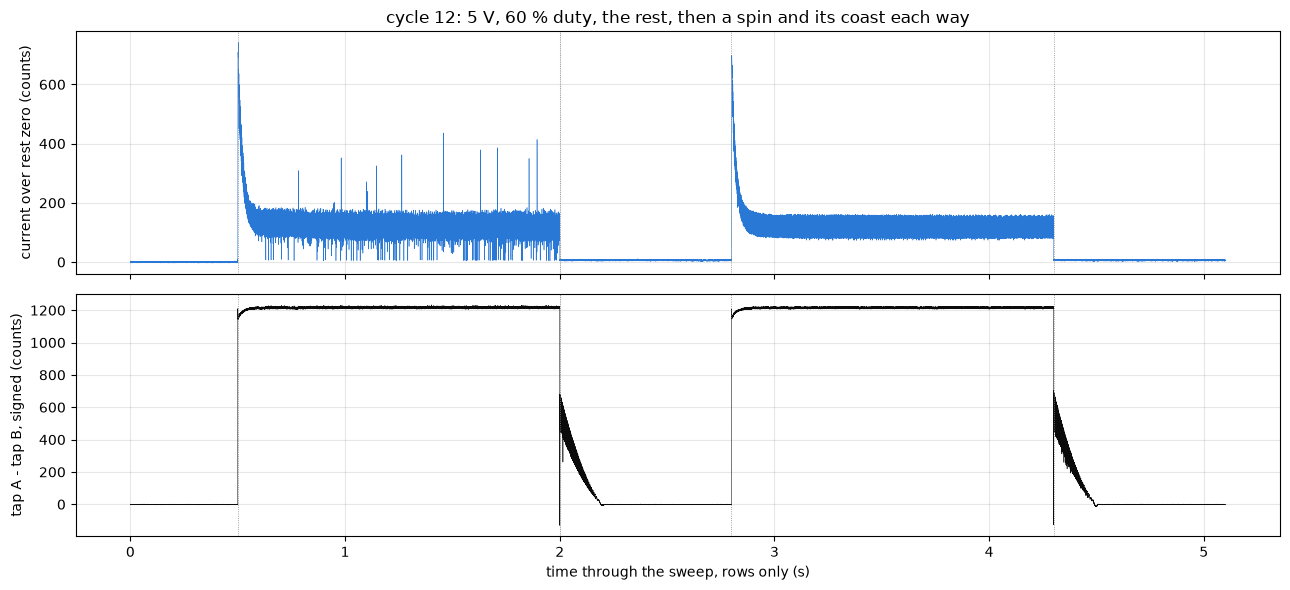

In [3]:
def cycle_folder(k):
    return CAPTURE / cycles.loc[cycles["k"] == k, "folder"].iloc[0]

def pairs(df):
    # (direction, spin rows, coast rows) for every spin and the coast chained to it: a coast is a
    # driven segment with a zero command, and its spin is the segment before it
    out = []
    for seg, co in df[df["seg"] > 0].groupby("seg"):
        if int(co["cmd_duty_q15"].iloc[0]) != 0:
            continue
        out.append((int(co["dir"].iloc[0]), df[df["seg"] == seg - 1], co))
    return out

def cut_row(co):
    # the cut: the first row of the coast's stream with no drive, the rows before it being the drive's tail
    z = np.flatnonzero(co["duty_counts"].to_numpy() == 0)
    return int(z[0]) if len(z) else None

K_SHOW = int(cycles[(cycles["volts_set"] == 5.0) & (cycles["duty_pct"] == 60)]["k"].iloc[0])   # the cycle the figures walk through
df, meta = tel.load(cycle_folder(K_SHOW), BOARD)       # checks the sense block against the board entry
zero_show = tel.baseline(df)["current_raw"].median()   # the cycle's torque-off zero
ts = np.arange(len(df)) / FS                           # time through the sweep as rows, since `tick` restarts at each segment
edges = np.flatnonzero(np.diff(df["seg"].to_numpy()) != 0) + 1
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].plot(ts, df["current_raw"] - zero_show, lw=0.4, color=BLUE); ax[0].set_ylabel("current over rest zero (counts)")
ax[1].plot(ts, (df["vmotor_a"] - df["vmotor_b"]) * df["dir"].where(df["seg"] > 0, 1), lw=0.4, color=INK)
ax[1].set_ylabel("tap A - tap B, signed (counts)"); ax[1].set_xlabel("time through the sweep, rows only (s)")
for a in ax:
    for e in edges:
        a.axvline(e / FS, color=MUTED, lw=0.6, ls=":")  # segment edges, where the streams meet
    a.grid(alpha=0.3)
ax[0].set_title(f"cycle {K_SHOW}: {cycles.loc[cycles['k'] == K_SHOW, 'volts_set'].iloc[0]:g} V, 60 % duty, the rest, then a spin and its coast each way")
plt.tight_layout(); plt.show()

In each spin the current jumps to a start-up peak and falls to a steady band within about 100 ms, while the terminal difference reads the rail. In each coast the current falls to its zero and the terminal difference carries the back-EMF down to zero as the rotor stops. The forward spin of this cycle is one where the current drops out. It falls to zero for single rows and also spikes upward now and then, and the reverse spin does neither. The start of each spin, the end of each spin and the coast each feed one route below.

### The results carried in

$K_e$ and the per-spin list from bemf-coast, and the current chain from current-scale.

In [4]:
BC = results.read("2-motor", "bemf-coast", pair=MOTOR.key)            # Ke and one entry per spin and coast pair
CS = results.read("1-board", "current-scale", pair=BOARD.key)         # counts per amp and the in-drive offset
TC = results.read("1-board", "terminal-chain", pair=BOARD.key)        # counts per volt of tap difference
KE = BC["ke_v_s_per_rad"]["value"]                                    # V s/rad, the coast route
KT = KE                                                               # N m/A: the torque constant is the same number in SI units
A_PER_COUNT = 1 / CS["counts_per_a"]["value"]                          # amps per count over the zero
I_DRIVE_OFFSET = CS["drive_offset_counts"]["value"]                   # counts the chain reads over its rest zero under drive
V_PER_COUNT = 1 / TC["terminal_counts_per_v"]["value"]                 # volts of tap difference per count
SPIN = pd.DataFrame(BC["cycles"]).rename(columns={"direction": "dir"})  # bemf-coast's reading of every spin, one row each
SPIN["w"] = 2 * np.pi * SPIN["spin_speed_rev_s"]                        # the spin's speed in rad/s, counted in its current's ripple
SPIN["i0"] = SPIN["i_spin_a"]                                          # the no-load current, through current-scale's in-drive offset
SPIN["i0_oz"] = SPIN["i_spin_open_zero_a"]                             # the same through the open bridge's own zero
print(f"Ke = Kt = {KE * 1e3:.4f} mV s/rad ({BC['ke_v_s_per_rad']['lo'] * 1e3:.4f} to {BC['ke_v_s_per_rad']['hi'] * 1e3:.4f}), "
      f"trend {BC['ke_speed_trend_pct_per_100_rev_s']['value']:+.2f} % per 100 rev/s under the rest zero and {BC['ke_speed_trend_by_zero_pct_per_100_rev_s']['none']['value']:+.2f} under none, from {BC['capture']}")
print(f"current {CS['counts_per_a']['value']:.1f} counts/A, in-drive offset {I_DRIVE_OFFSET:+.1f} counts "
      f"({CS['drive_offset_counts']['lo']:+.1f} to {CS['drive_offset_counts']['hi']:+.1f}); taps {TC['terminal_counts_per_v']['value']:.2f} counts/V")
show(SPIN[["k", "level", "duty", "dir", "spin_speed_rev_s", "i_spin_a", "i_spin_open_zero_a", "spin_open_per_s", "speed_drift_pct", "i_drift_ma"]], n=4)

Ke = Kt = 1.1684 mV s/rad (1.1609 to 1.1745), trend -0.26 % per 100 rev/s under the rest zero and +0.02 under none, from telemetry/mg90-b__dev-v006-2A-D/bemf-coast/capture-1
current 1135.0 counts/A, in-drive offset +5.3 counts (+4.4 to +6.1); taps 248.37 counts/V


,k,level,duty,dir,spin_speed_rev_s,i_spin_a,i_spin_open_zero_a,spin_open_per_s,speed_drift_pct,i_drift_ma
0,0,5.000,15,1,63.940,0.067,0.067,0.000,0.176,-0.835
1,0,5.000,15,-1,64.946,0.065,0.065,0.000,0.042,0.002
2,1,5.000,15,1,64.347,0.068,0.066,0.000,0.002,0.656
3,1,5.000,15,-1,64.931,0.066,0.065,0.000,0.144,-0.183


$K_e$ is 1.1684 mV s/rad by the coast route. In SI units the torque constant $K_t$ is the same number in N m/A, so 1 mA of current is 1.17 uN m of torque. bemf-coast leaves open whether $K_e$ falls with speed, about 1 % over the range under one zero of the tap difference and flat under another, and carries that span as its bounds, 0.6 % wide; so a single $K_t$ is good to about 0.6 % over this speed range either way. Its clock, the board's tick, is a further 1 % by its class, not measured, which scales every speed here and $K_t$ together and leaves every shape alone. The per-spin list has sixty rows, one per spin.

## Method

A few symbols carry the notebook. $\omega$ (omega) is the motor's speed in radians per second. $\alpha$ (alpha) is a rate of change of that speed in radians per second squared, a deceleration in a coast and an acceleration in a spin-up. $J$ is the rotor's inertia in kg m$^2$, and the values here are a few times $10^{-9}$ kg m$^2$. $I_0$ is the no-load current, the current of a settled spin, and the torque from a current $I$ is $K_t I$.

In a coast nothing drives the rotor and the drag $T_f(\omega)$ slows it,

$$J\,\alpha = T_f(\omega)$$

In a settled spin the drive holds the speed against the drag,

$$K_t\,I_0(\omega) = T_f(\omega)$$

and in a spin-up the drive's torque beyond the drag speeds the rotor up,

$$K_t\,\left(I - I_0(\omega)\right) = J\,\alpha$$

If the drag is the same function of speed in all three, the first two give $J = K_t I_0 / \alpha$ at every speed, and the third gives the same $J$.

Every spin and coast goes through the same steps.

1. The spin. The speed and the current of each settled spin come from bemf-coast's per-cycle list, over the last 200 ms of the spin. The speed is the ripple of the spin's current counted over the window, six ripple events per revolution. bemf-coast found the window settled in speed to 0.03 % on average, and the current moved -0.13 mA on average across it.
2. The coast's speed. The coast's EMF from the cut, with the rows where the brush path opens bridged as bemf-coast does, is cut into windows of the whole number of ripple cycles closest to 5 ms, end to end down the coast until the speed falls under 30 rev/s. Each window's speed is its cycles over its time. The deceleration between two consecutive windows is the change of speed over the time between their middles, at the mean of the two speeds. $K_e$ does not enter, so its trend with speed does not either.
3. The deceleration at the cut. The ripple's upward crossings over the stretch where the speed falls by 30 % give the shaft's angle in steps of a sixth of a turn. The speed through that stretch is taken as a parabola in time from the cut, starting at the spin's own counted speed, and its slope at the cut is the deceleration there. The speed at the cut is pinned because the coasts under 200 rev/s hold too few crossings to fit it as well. On the faster coasts it can be left free, and the check below compares the two.
4. The spin-up. The spin's current is cut into windows the same way, looking back from the settled speed toward the start, so each window is seeded by the one after it. The acceleration between windows is read as in the coast. The current in each window less the settled curve $I_0(\omega)$ of its level at that speed is what goes into speeding the rotor up.

The inertia then comes three ways. The ratio $K_t I_0 / \alpha$ with the deceleration at the cut, spin by spin, is the plan's route. A line of $K_t I_0$ on the deceleration at the cut over the spins of a level has $J$ as its slope, and its intercept is a torque the coast's deceleration does not account for. The spin-up gives both a ratio and a line the same way.

The method changed from the plan in four places once the data came in.

- The plan reduced each spin itself over its last 300 ms, with an exponential fitted to the current's tail to judge the settle. bemf-coast found that fit running into its bounds on 11 of the 60 spins, since the current keeps sliding slowly to the end of the spin, and it read the settle directly. This notebook takes the spin's speed and current from bemf-coast's list over the same 200 ms window and carries the slide as a margin.
- The plan fitted each coast's EMF with a constant plus a viscous drag, $dE/dt = -a - E/\tau$. On this data that shape misses at both ends of the speed range, as the Results show. The coast's speed is now counted in its ripple window by window, and the shape of the drag is chosen from the decelerations of all the coasts together.
- The plan took the deceleration at the spin's EMF from that per-coast fit. The drag at a given speed turns out to be higher just after the cut than later in the coast, so the deceleration paired with each spin is now read from the coast's first stretch alone.
- The spin-up route is new. It reads $J$ from the drive's own current, with no coast in it.

### The estimators

One function per step, applied to every spin and coast below.

In [5]:
COAST_FROM = 20                    # rows past the cut the coast's read starts, 1 ms, after the taps settle
TURN_V = 0.05                      # V, under this the rotor has about stopped
NBH = 41                           # rows, about 2 ms, the neighborhood an EMF row is compared with
OPEN_FRAC = 0.3                    # a coast row under this share of its neighborhood's mean is an open brush path
WIN_MS = 5                         # the coast's windows of whole ripple cycles are the number closest to this long
MIN_CYCLES = 3                     # and never fewer than this
FLOOR_REV_S = 30                   # rev/s, the windows stop here, where three cycles take 30 ms and run into the stop
DROP = 0.3                         # the fit at the cut runs over the stretch where the speed falls by this share
UP_FLOOR_REV_S = 40                # rev/s, the spin-up's windows stop here, looking back from the settled speed
UP_WIN_MS = 4                      # the spin-up's windows of whole ripple cycles

def crossings(x, f0, frac=0.35):
    # the upward zero crossings of the line near f0, in rows from the start of x and interpolated to a fraction of a row:
    # a second-order band-pass f0 x (1 +/- frac) run forward and back, so it shifts no crossing in time, and the first
    # and last crossing dropped as the filter's edge
    hi = min(f0 * (1 + frac), 0.95 * FS / 2)
    sos = butter(2, [f0 * (1 - frac), hi], btype="band", fs=FS, output="sos")
    y = sosfiltfilt(sos, np.asarray(x, float) - np.mean(x))
    s = np.flatnonzero((y[:-1] < 0) & (y[1:] >= 0))
    return (s + (-y[s]) / (y[s + 1] - y[s]))[1:-1]

def read_window(x, start, f_seed, target_ms):
    # (mean frequency, first row, last row, cycles) over the whole ripple cycles from `start` closest to target_ms, at least
    # MIN_CYCLES, the band-pass centered on the window's own mean frequency by repeating the count, as in bemf-coast
    f = f_seed
    for _ in range(6):
        n = max(MIN_CYCLES, int(round(target_ms / 1e3 * f)))           # cycles in the window at the current estimate
        stop = start + int((n + 3) * FS / f * 1.3)                       # the stretch the filter runs over, past the window
        if stop > len(x):
            return np.nan, 0, 0, 0
        tc = crossings(x[start:stop], f)
        if len(tc) < n + 1:
            return np.nan, 0, 0, 0
        tc = tc[:n + 1]                                                  # the window: n whole cycles from the first crossing
        f_new = n / ((tc[-1] - tc[0]) / FS)
        done = abs(f_new / f - 1) < 1e-4
        f = f_new
        if done:
            break
    return f, start + tc[0], start + tc[-1], n

def walk(x, start, f_seed, target_ms, floor_rev_s, stop):
    # windows end to end from `start`, each seeded by the last, until the speed falls under the floor or a window passes `stop`
    out, f = [], f_seed
    while True:
        f, i0, i1, n = read_window(x, start, f, target_ms)
        if not np.isfinite(f) or f / N_R < floor_rev_s or i1 > stop:
            return out
        out.append((i0, i1, f, n))
        start = int(np.ceil(i1))

def open_rows(e):
    # coast rows where the EMF falls under OPEN_FRAC of its neighborhood while the rotor still turns, past the first 1 ms
    ref = np.convolve(e, np.ones(NBH) / NBH, mode="same")
    bad = (e < OPEN_FRAC * ref) & (ref > TURN_V)
    bad[:COAST_FROM] = False
    return bad

def bridge(e, bad):
    # the EMF with each open row replaced by a line between its neighbors
    if not bad.any():
        return e.copy()
    x = np.arange(len(e))
    out = e.copy()
    out[bad] = np.interp(x[bad], x[~bad], e[~bad])
    return out

def cut_fit(e, w_spin, free=False):
    # the deceleration at the cut. The ripple's crossings over the stretch where the speed falls by DROP give the shaft's
    # angle in steps of 1/N_R of a turn, k crossings at times t_k. The speed is taken as a parabola in time from the cut,
    # w(t) = w0 - a t + c t^2, so the crossing count is k(t) = k0 + (N_R / 2 pi)(w0 t - a t^2 / 2 + c t^3 / 3).
    # With `free` False, w0 is pinned to the spin's counted speed and the fit finds the phase k0, a and c; with `free`
    # True, w0 is fitted too. Returns (a in rad/s^2, w0, crossings used, stretch in s).
    f0 = w_spin * N_R / (2 * np.pi)
    span = max(0.010, 8 / f0)                                            # a first stretch of at least eight cycles
    for _ in range(4):
        n = int(span * FS) + COAST_FROM
        fc = f0 * (1 - DROP / 2)                                         # the band sits on the middle of the stretch's speeds
        tc = crossings(e[COAST_FROM:n + int(2 * FS / fc)], fc, frac=0.4)
        tc = tc[tc < n - COAST_FROM]
        t = (tc + COAST_FROM) / FS                                       # seconds from the cut
        k = np.arange(len(t), dtype=float)
        g = N_R / (2 * np.pi)
        if free:
            X = np.c_[np.ones_like(t), g * t, -g * t ** 2 / 2, g * t ** 3 / 3]
            b = np.linalg.lstsq(X, k, rcond=None)[0]
            w0, a = b[1], b[2]
        else:
            X = np.c_[np.ones_like(t), -g * t ** 2 / 2, g * t ** 3 / 3]
            b = np.linalg.lstsq(X, k - g * w_spin * t, rcond=None)[0]
            w0, a = w_spin, b[1]
        span = float(np.clip(DROP * w0 / a, 8 / f0, 0.04))               # the next pass's stretch, where the speed falls by DROP
    return float(a), float(w0), len(t), span

In [6]:
def reduce_cycle(C):
    # one cycle: the coast's windows, the fit at the cut and the spin-up's windows, per direction
    df, meta = tel.load(cycle_folder(C["k"]), BOARD)
    rest = tel.baseline(df)
    zero_e = (rest["vmotor_a"] - rest["vmotor_b"]).median()             # the tap difference at rest, no EMF
    zero_i = rest["current_raw"].median()                               # the current channel's torque-off zero
    win, cut, up = [], [], []
    for d, sp, co in pairs(df):
        s = SPIN[(SPIN["k"] == C["k"]) & (SPIN["dir"] == d)].iloc[0]
        tag = {"k": int(C["k"]), "level": float(C["volts_set"]), "duty": int(C["duty_pct"]), "dir": d}
        # the coast's EMF from the cut, open rows bridged, as in bemf-coast
        z = cut_row(co)
        e_read = (((co["vmotor_a"] - co["vmotor_b"]) * d).to_numpy(float)[z:] - zero_e) * V_PER_COUNT
        e = bridge(e_read, open_rows(e_read))
        smooth = np.convolve(e, np.ones(NBH) / NBH, mode="same")
        stop = COAST_FROM + np.flatnonzero(smooth[COAST_FROM:] < TURN_V)[0]   # the rotor about stopped
        # windows end to end down the coast, the speed in each counted in its ripple, the time at its middle
        for i0, i1, f, n in walk(e, COAST_FROM, s["spin_speed_rev_s"] * N_R * 0.95, WIN_MS, FLOOR_REV_S, stop):
            win.append({**tag, "t0": i0 / FS, "t1": i1 / FS, "w": 2 * np.pi * f / N_R, "cycles": n})
        # the deceleration at the cut, with the speed pinned to the spin's count, and with it free as a check
        a, _, n, span = cut_fit(e, s["w"])
        a_free, w_free, _, _ = cut_fit(e, s["w"], free=True)
        cut.append({**tag, "alpha_cut": a, "crossings": n, "span_ms": span * 1e3, "alpha_free": a_free, "w_free": w_free})
        # the spin-up: windows looking back from the settled speed toward the start, the current over the same rows
        x = sp["current_raw"].to_numpy(float)
        amps = (x - zero_i - I_DRIVE_OFFSET) * A_PER_COUNT
        xr = x[::-1].copy()                                             # reversed in time, the speed falls from the settled one
        for r0, r1, f, n in walk(xr, 200, s["spin_speed_rev_s"] * N_R, UP_WIN_MS, UP_FLOOR_REV_S, len(xr)):
            a0, a1 = len(x) - r1, len(x) - r0                           # the window's rows forward in time
            up.append({**tag, "t0": a0 / FS, "t1": a1 / FS, "w": 2 * np.pi * f / N_R, "i": amps[int(a0):int(np.ceil(a1))].mean()})
    return win, cut, up

parts = [reduce_cycle(C) for _, C in cycles.iterrows()]
WIN = pd.DataFrame([r for p in parts for r in p[0]])
CUT = pd.DataFrame([r for p in parts for r in p[1]]).merge(SPIN[["k", "dir", "w", "spin_speed_rev_s", "i0", "i0_oz", "spin_open_per_s"]], on=["k", "dir"])
UP = pd.DataFrame([r for p in parts for r in p[2]])

def slopes(g, key):
    # the deceleration between consecutive windows of one coast (or the acceleration of one spin-up), at the mean of their
    # speeds and the middle of their times: the mean speed of a window of whole cycles is its speed at its middle
    rows = []
    for _, h in g.groupby(["k", "dir"]):
        h = h.sort_values("t0")
        tm = ((h["t0"] + h["t1"]) / 2).to_numpy(); w = h["w"].to_numpy()
        for j in range(len(h) - 1):
            row = {c: h[c].iloc[0] for c in ("k", "level", "duty", "dir")}
            row.update(t=(tm[j] + tm[j + 1]) / 2, w=(w[j] + w[j + 1]) / 2, **{key: (w[j] - w[j + 1]) / (tm[j + 1] - tm[j]) * (1 if key == "alpha" else -1)})
            if "i" in h:
                row["i"] = (h["i"].iloc[j] + h["i"].iloc[j + 1]) / 2
            rows.append(row)
    return pd.DataFrame(rows)

DEC = slopes(WIN, "alpha")                                               # the coast's deceleration, rad/s^2
ACC = slopes(UP, "acc")                                                  # the spin-up's acceleration, rad/s^2
for t_ in (DEC, ACC, CUT):
    t_["rev_s"] = t_["w"] / (2 * np.pi)
print(f"{len(WIN)} coast windows, {len(DEC)} decelerations from {DEC['rev_s'].min():.0f} to {DEC['rev_s'].max():.0f} rev/s; "
      f"{len(CUT)} fits at the cut on {CUT['crossings'].min()} to {CUT['crossings'].max()} crossings over {CUT['span_ms'].min():.0f} to {CUT['span_ms'].max():.0f} ms; "
      f"{len(UP)} spin-up windows")

705 coast windows, 645 decelerations from 44 to 490 rev/s; 60 fits at the cut on 5 to 107 crossings over 17 to 40 ms; 14517 spin-up windows


### One cycle through the estimators

The forward spin and coast of the cycle above. Left, the spin-up's windows, speed and current, with the settled values dotted. Middle, the coast's windows, the spin's speed pinned at the cut and the slope there. Right, the deceleration between consecutive windows of this coast against speed, with the one at the cut.

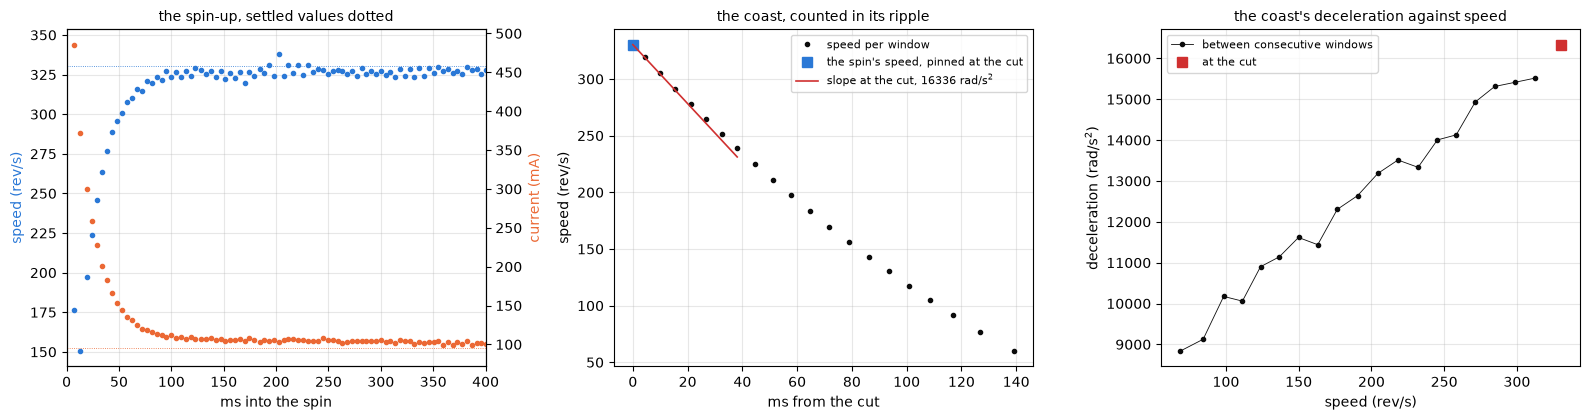

cycle 12 direction +1: spin 330.3 rev/s at 94.9 mA; coast windows 20; at the cut 16336 rad/s^2 from 63.0 crossings over 38 ms; left free the fit puts the cut at -0.08 % of the spin's speed


In [7]:
d0 = 1                                                                    # the forward spin and coast of cycle K_SHOW
s0 = SPIN[(SPIN["k"] == K_SHOW) & (SPIN["dir"] == d0)].iloc[0]
c0 = CUT[(CUT["k"] == K_SHOW) & (CUT["dir"] == d0)].iloc[0]
w0 = WIN[(WIN["k"] == K_SHOW) & (WIN["dir"] == d0)]
u0 = UP[(UP["k"] == K_SHOW) & (UP["dir"] == d0)]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
# left: the spin-up's windows, speed and current
ax[0].plot((u0["t0"] + u0["t1"]) / 2 * 1e3, u0["w"] / (2 * np.pi), ".", color=BLUE, label="speed per window")
ax[0].axhline(s0["spin_speed_rev_s"], color=BLUE, lw=0.6, ls=":")
a2 = ax[0].twinx(); a2.plot((u0["t0"] + u0["t1"]) / 2 * 1e3, u0["i"] * 1e3, ".", color=ORANGE, label="current per window")
a2.axhline(s0["i0"] * 1e3, color=ORANGE, lw=0.6, ls=":"); a2.set_ylabel("current (mA)", color=ORANGE)
ax[0].set_xlim(0, 400); ax[0].set_xlabel("ms into the spin"); ax[0].set_ylabel("speed (rev/s)", color=BLUE)
ax[0].set_title("the spin-up, settled values dotted", fontsize=10)
# middle: the coast's windows down to the floor, with the parabola at the cut over its stretch
tt = np.linspace(0, c0["span_ms"] / 1e3, 50)
ax[1].plot((w0["t0"] + w0["t1"]) / 2 * 1e3, w0["w"] / (2 * np.pi), ".", color=INK, label="speed per window")
ax[1].plot(0, s0["spin_speed_rev_s"], "s", color=BLUE, ms=7, label="the spin's speed, pinned at the cut")
ax[1].plot(tt * 1e3, (s0["w"] - c0["alpha_cut"] * tt) / (2 * np.pi), "-", color=RED, lw=1.2, label=f"slope at the cut, {c0['alpha_cut']:.0f} rad/s$^2$")
ax[1].set_xlabel("ms from the cut"); ax[1].set_ylabel("speed (rev/s)"); ax[1].set_title("the coast, counted in its ripple", fontsize=10); ax[1].legend(fontsize=8)
# right: the deceleration between consecutive windows of this coast against speed
h = DEC[(DEC["k"] == K_SHOW) & (DEC["dir"] == d0)]
ax[2].plot(h["rev_s"], h["alpha"], ".-", color=INK, lw=0.6, label="between consecutive windows")
ax[2].plot(s0["spin_speed_rev_s"], c0["alpha_cut"], "s", color=RED, ms=7, label="at the cut")
ax[2].set_xlabel("speed (rev/s)"); ax[2].set_ylabel("deceleration (rad/s$^2$)"); ax[2].set_title("the coast's deceleration against speed", fontsize=10); ax[2].legend(fontsize=8)
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"cycle {K_SHOW} direction +1: spin {s0['spin_speed_rev_s']:.1f} rev/s at {s0['i0'] * 1e3:.1f} mA; coast windows {len(w0)}; "
      f"at the cut {c0['alpha_cut']:.0f} rad/s^2 from {c0['crossings']} crossings over {c0['span_ms']:.0f} ms; "
      f"left free the fit puts the cut at {c0['w_free'] / s0['w'] * 100 - 100:+.2f} % of the spin's speed")

The rotor reaches its speed within about 80 ms while the current falls from its start-up peak, and the current is still a few milliamps over its settled value after the speed has flattened. In the coast the speed falls along a gently curved line, faster at first. The deceleration between windows rises with speed, and the one at the cut sits a little above where the windows' trend would put it at that speed, which the Results come back to.

Left free on the faster coasts, the speed at the cut against the spin's count.

In [8]:
dense = CUT[CUT["crossings"] >= 30].copy()                                # the fits with enough crossings to free the speed at the cut
dense["free_pct"] = (dense["w_free"] / dense["w"] - 1) * 100            # the fitted speed at the cut over the spin's count, less one
print(f"speed at the cut, left free, over the spin's count: median {dense['free_pct'].median():+.2f} %, 16th to 84th percentile "
      f"{dense['free_pct'].quantile(0.16):+.2f} to {dense['free_pct'].quantile(0.84):+.2f} %, all {dense['free_pct'].min():+.2f} to {dense['free_pct'].max():+.2f} %, "
      f"over {len(dense)} coasts from {dense['rev_s'].min():.0f} rev/s up")
print(f"pinned, the deceleration at the cut spreads {CUT.groupby(['level', 'duty'])['alpha_cut'].agg(lambda x: x.std() / x.mean() * 100).median():.1f} % "
      f"within a rung in the median, over {CUT['crossings'].min()} to {CUT['crossings'].max()} crossings")

speed at the cut, left free, over the spin's count: median -0.01 %, 16th to 84th percentile -0.11 to +0.15 %, all -3.96 to +0.69 %, over 30 coasts from 214 rev/s up
pinned, the deceleration at the cut spreads 2.8 % within a rung in the median, over 5 to 107 crossings


Left free, the speed at the cut lands within -0.11 to +0.15 % of the spin's count on the thirty coasts from 214 rev/s up, from the 16th to the 84th percentile, with one coast at -4 %. So the rotor reaches the cut at the spin's speed, which is what the pin assumes. It also settles part of a question bemf-coast left open. Its spin route read $K_e$ 0.20 % under its coast route, and the speed carried across the gap between the streams is not where that comes from. Pinned, the deceleration at the cut spreads 2.8 % within a rung in the median.

## Results

### No-load current against speed

Every spin's current against its speed, both levels and both directions, with a curve per level. Beside it, the 7.4 V rungs less the 5.0 V curve at the same speed, through each zero. The thing to see is the shape of the rise and whether the two levels share a curve.

5 V: 65.2 to 99.1 mA over 64 to 338 rev/s; I0 = 74.3 +/- 0.4 mA + 17.62 +/- 0.56 mA x ln(w / 100 rev/s), rms 1.71 mA
    a + b w        rms 3.15 mA
    a + b sqrt(w)  rms 2.28 mA
    a + b ln(w)    rms 1.71 mA
7.4 V: 83.7 to 119.1 mA over 105 to 510 rev/s; I0 = 84.0 +/- 0.9 mA + 19.92 +/- 0.91 mA x ln(w / 100 rev/s), rms 2.64 mA
    a + b w        rms 4.21 mA
    a + b sqrt(w)  rms 3.31 mA
    a + b ln(w)    rms 2.64 mA


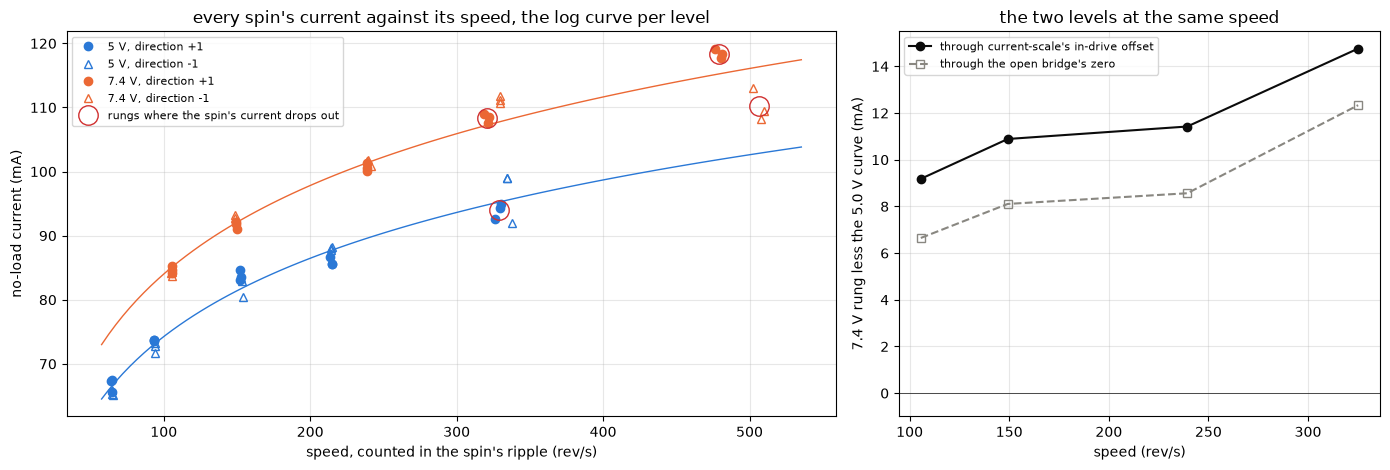

7.4 V over the 5.0 V curve at the same speed (mA): {15: 9.2, 20: 10.9, 30: 11.4, 40: 14.8} | through the open bridge's zero: {15: 6.6, 20: 8.1, 30: 8.6, 40: 12.3}
within a rung the spins spread 0.63 mA in the median (0.10 to 4.10); across the 200 ms window the current moves -0.13 mA on average (sd 0.60)


In [9]:
RUNG = SPIN.groupby(["level", "duty", "dir"]).agg(n=("i0", "size"), rev_s=("spin_speed_rev_s", "mean"), rev_sd=("spin_speed_rev_s", "std"),
                                                 i0=("i0", "mean"), i0_sd=("i0", "std"), i0_oz=("i0_oz", "mean"), opens=("spin_open_per_s", "mean"),
                                                 drift_ma=("i_drift_ma", "mean")).reset_index()
OPEN_RUNGS = RUNG[RUNG["opens"] > 0][["level", "duty", "dir"]]            # the rungs where the spin's current drops out
W_REF = 2 * np.pi * 100                                                   # rad/s, 100 rev/s, where the log curve's constant sits

def i0_log(w, a, b):
    # the no-load current as a constant at 100 rev/s plus a term in the log of the speed
    return a + b * np.log(w / W_REF)

def fit_level(g, col):
    p, cov = curve_fit(i0_log, g["w"], g[col], p0=[0.08, 0.02])
    return p, np.sqrt(np.diag(cov)), float(np.sqrt(np.mean((g[col] - i0_log(g["w"], *p)) ** 2)))

FORMS = {"a + b w": lambda w, a, b: a + b * w, "a + b sqrt(w)": lambda w, a, b: a + b * np.sqrt(w), "a + b ln(w)": lambda w, a, b: a + b * np.log(w / W_REF)}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
I0FIT = {}
x = np.linspace(SPIN["w"].min() * 0.9, SPIN["w"].max() * 1.05, 100)
for v in LEVELS:
    g = SPIN[SPIN["level"] == v]
    I0FIT[v] = fit_level(g, "i0")
    for d in (1, -1):
        h = g[g["dir"] == d]
        ax[0].plot(h["spin_speed_rev_s"], h["i0"] * 1e3, MARK[d], ms=6, color=COLOR[v], mfc=COLOR[v] if d == 1 else "none", label=f"{v:g} V, direction {d:+d}")
    ax[0].plot(x / (2 * np.pi), i0_log(x, *I0FIT[v][0]) * 1e3, "-", lw=1, color=COLOR[v])
    print(f"{v:g} V: {g['i0'].min() * 1e3:.1f} to {g['i0'].max() * 1e3:.1f} mA over {g['spin_speed_rev_s'].min():.0f} to {g['spin_speed_rev_s'].max():.0f} rev/s; "
          f"I0 = {I0FIT[v][0][0] * 1e3:.1f} +/- {I0FIT[v][1][0] * 1e3:.1f} mA + {I0FIT[v][0][1] * 1e3:.2f} +/- {I0FIT[v][1][1] * 1e3:.2f} mA x ln(w / 100 rev/s), rms {I0FIT[v][2] * 1e3:.2f} mA")
    for name, f in FORMS.items():
        p, _ = curve_fit(f, g["w"], g["i0"], p0=[0.05, 0.001], maxfev=20000)
        print(f"    {name:14s} rms {np.sqrt(np.mean((g['i0'] - f(g['w'], *p)) ** 2)) * 1e3:.2f} mA")
op = RUNG.merge(OPEN_RUNGS)
ax[0].plot(op["rev_s"], op["i0"] * 1e3, "o", ms=14, mfc="none", color=RED, label="rungs where the spin's current drops out")
ax[0].set_xlabel("speed, counted in the spin's ripple (rev/s)"); ax[0].set_ylabel("no-load current (mA)")
ax[0].set_title("every spin's current against its speed, the log curve per level"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
# right: the 7.4 V rungs against the 5.0 V curve at the same speed, both zeros
m7 = RUNG[(RUNG["level"] == 7.4)].groupby("duty").agg(w=("rev_s", "mean"), i0=("i0", "mean"), i0_oz=("i0_oz", "mean")).reset_index()
m7["w"] = 2 * np.pi * m7["w"]
m7 = m7[m7["w"] <= SPIN[SPIN["level"] == 5.0]["w"].max()]                   # where the speeds overlap
FIT_OZ = {v: fit_level(SPIN[SPIN["level"] == v], "i0_oz") for v in LEVELS}
m7["gap"] = (m7["i0"] - i0_log(m7["w"], *I0FIT[5.0][0])) * 1e3
m7["gap_oz"] = (m7["i0_oz"] - i0_log(m7["w"], *FIT_OZ[5.0][0])) * 1e3
ax[1].plot(m7["w"] / (2 * np.pi), m7["gap"], "o-", color=INK, label="through current-scale's in-drive offset")
ax[1].plot(m7["w"] / (2 * np.pi), m7["gap_oz"], "s--", color=MUTED, mfc="none", label="through the open bridge's zero")
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_ylim(bottom=-1)
ax[1].set_xlabel("speed (rev/s)"); ax[1].set_ylabel("7.4 V rung less the 5.0 V curve (mA)"); ax[1].set_title("the two levels at the same speed"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("7.4 V over the 5.0 V curve at the same speed (mA):", dict(zip(m7["duty"], m7["gap"].round(1))), "| through the open bridge's zero:", dict(zip(m7["duty"], m7["gap_oz"].round(1))))
print(f"within a rung the spins spread {RUNG['i0_sd'].median() * 1e3:.2f} mA in the median ({RUNG['i0_sd'].min() * 1e3:.2f} to {RUNG['i0_sd'].max() * 1e3:.2f}); "
      f"across the 200 ms window the current moves {SPIN['i_drift_ma'].mean():+.2f} mA on average (sd {SPIN['i_drift_ma'].std():.2f})")

The no-load current rises from 65 mA at 64 rev/s to 99 mA at 338 rev/s at 5.0 V, and from 84 mA at 105 rev/s to 119 mA at 510 rev/s at 7.4 V. The rise is steep at low speed and flattens at high speed. Of three two-term curves, a constant plus a term in the log of the speed fits best at both levels, 1.7 mA rms at 5.0 V and 2.6 mA at 7.4 V, against 2.3 and 3.3 mA for a square root and 3.2 and 4.2 mA for a straight line. The log describes the shape over the measured range and is not a drag law I know of, so it should not be carried outside that range. At 5.0 V it reads 74.3 mA at 100 rev/s plus 17.6 mA per unit of $\ln \omega$, and at 7.4 V 84.0 mA plus 19.9 mA. Within a rung the three spins of one direction spread 0.6 mA in the median.

The two levels do not share a curve. At the same speed the 7.4 V spins draw 9 to 15 mA more than the 5.0 V curve, about 12 to 16 %, and the gap grows with speed. Through the open bridge's zero the gap is about 2.5 mA smaller at every rung, still 7 to 12 mA. A gap this size is either a drag that only the drive at 7.4 V carries, or a reading of the current that depends on the rail. The coast's drag below separates the rotor from the drive.

On the zero, this notebook carries the current through current-scale's in-drive offset, `i_spin_a`. The sample is taken in the middle of the drive's on time, with one high side and the opposite low side on, the same state the bridge holds through current-scale's DC laps. The open bridge has every output off, a different state. The open bridge's zero would lower every 5.0 V current by 0.7 mA and every 7.4 V current by 3.4 mA. The result file carries both, and that 0.7 to 3.4 mA is part of the uncertainty of every current here.

### The open rows and the two directions

The three conditions where the spin's current drops out are where the two directions split. Left, direction -1 less +1 in the spin's current per rung, with the change the level's curve gives for the speed difference between the directions alone. Right, the coast's deceleration in direction +1 over direction -1 at the same speed, with no drive at all. The thing to see is whether the current split follows the speed split along the curve, and whether the coast shows a split of its own.

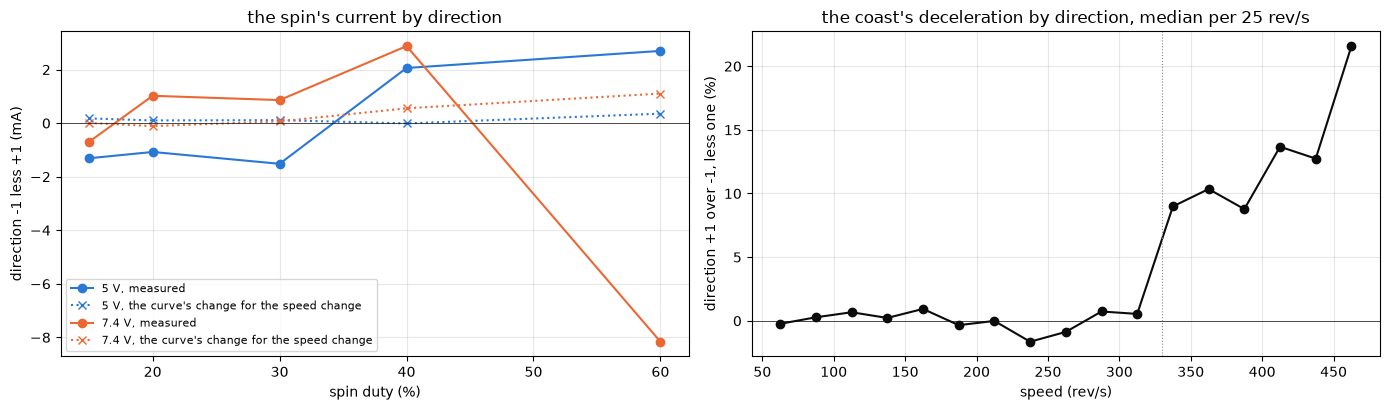

5 V 15 %: -1 runs +1.01 % faster and draws -1.31 mA, the curve says +0.18 mA for that speed; drops out 0/s in +1 and 0/s in -1
5 V 20 %: -1 runs +0.58 % faster and draws -1.08 mA, the curve says +0.10 mA for that speed; drops out 0/s in +1 and 0/s in -1
5 V 30 %: -1 runs +0.64 % faster and draws -1.52 mA, the curve says +0.11 mA for that speed; drops out 0/s in +1 and 0/s in -1
5 V 40 %: -1 runs -0.05 % faster and draws +2.06 mA, the curve says -0.01 mA for that speed; drops out 0/s in +1 and 0/s in -1
5 V 60 %: -1 runs +2.03 % faster and draws +2.70 mA, the curve says +0.35 mA for that speed; drops out 113/s in +1 and 0/s in -1
7.4 V 15 %: -1 runs +0.03 % faster and draws -0.70 mA, the curve says +0.01 mA for that speed; drops out 0/s in +1 and 0/s in -1
7.4 V 20 %: -1 runs -0.55 % faster and draws +1.02 mA, the curve says -0.11 mA for that speed; drops out 0/s in +1 and 0/s in -1
7.4 V 30 %: -1 runs +0.33 % faster and draws +0.86 mA, the curve says +0.07 mA for that speed; drops out 

In [10]:
g = RUNG.set_index(["level", "duty", "dir"])
split = pd.DataFrame({"speed_pct": (g.xs(-1, level="dir")["rev_s"] / g.xs(1, level="dir")["rev_s"] - 1) * 100,
                      "i0_ma": (g.xs(-1, level="dir")["i0"] - g.xs(1, level="dir")["i0"]) * 1e3,
                      "opens_p": g.xs(1, level="dir")["opens"], "opens_m": g.xs(-1, level="dir")["opens"]})
# what the 5.0 V or 7.4 V log curve says the current should change for that speed change, with no change in drag
split["i0_curve_ma"] = [(i0_log(2 * np.pi * g.loc[(v, du, -1), "rev_s"], *I0FIT[v][0]) - i0_log(2 * np.pi * g.loc[(v, du, 1), "rev_s"], *I0FIT[v][0])) * 1e3
                        for v, du in split.index]
# the coast's deceleration between windows by direction; above about 330 rev/s only the 60 % coasts at 7.4 V reach
DEC["bin"] = (DEC["rev_s"] // 25) * 25 + 12.5
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for v in LEVELS:
    s = split.xs(v, level="level")
    ax[0].plot(s.index, s["i0_ma"], "o-", color=COLOR[v], label=f"{v:g} V, measured")
    ax[0].plot(s.index, s["i0_curve_ma"], "x:", color=COLOR[v], label=f"{v:g} V, the curve's change for the speed change")
ax[0].axhline(0, color=INK, lw=0.5); ax[0].set_xlabel("spin duty (%)"); ax[0].set_ylabel("direction -1 less +1 (mA)")
ax[0].set_title("the spin's current by direction"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
both = DEC[DEC["rev_s"] > FLOOR_REV_S].groupby(["bin", "dir"])["alpha"].median().unstack("dir")
ax[1].plot(both.index, (both[1] / both[-1] - 1) * 100, "o-", color=INK)
ax[1].axhline(0, color=INK, lw=0.5); ax[1].axvline(330, color=MUTED, lw=0.8, ls=":")
ax[1].set_xlabel("speed (rev/s)"); ax[1].set_ylabel("direction +1 over -1, less one (%)")
ax[1].set_title("the coast's deceleration by direction, median per 25 rev/s"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
for (v, du), r in split.iterrows():
    print(f"{v:g} V {du:2d} %: -1 runs {r['speed_pct']:+.2f} % faster and draws {r['i0_ma']:+.2f} mA, the curve says {r['i0_curve_ma']:+.2f} mA for that speed; "
          f"drops out {r['opens_p']:.0f}/s in +1 and {r['opens_m']:.0f}/s in -1")
print("coast deceleration, +1 over -1 less one (%), per bin:", {int(b): round(x, 1) for b, x in ((both[1] / both[-1] - 1) * 100).dropna().items()})

Up to 330 rev/s the coast decelerates the same in both directions, within 1.6 % in every bin. Above that, where only the 60 % coasts at 7.4 V reach, direction +1 decelerates 9 to 22 % harder than direction -1 at the same speed. That is the free rotor with no current in the winding, so direction +1 has more drag at the top of the speed range. The brushes are the likely place, with moderate confidence. The openings bemf-coast found are mostly in direction +1 and mostly at these speeds, and a brush that bounces on the commutator both opens the circuit and rubs harder. The spin at 60 % on 7.4 V agrees. Direction -1 runs 5.7 % faster and draws 8.2 mA less, where the curve says a faster spin should draw 1.1 mA more, so direction +1 draws about 9 mA more than its speed alone asks for.

At 60 % on 5.0 V and 40 % on 7.4 V, the other two conditions where direction +1 drops out, direction -1 runs 2.0 and 2.8 % faster and draws 2.7 and 2.9 mA more. The curve accounts for 0.4 and 0.6 mA of that, so direction +1 sits about 2.3 mA under the curve there, and its coast shows no matching drop in drag. The dropouts take 0.6 to 0.7 % of the rows to near zero, which takes about 0.6 mA off the mean, plus whatever the rows lose while the current builds back. That is the size of the gap, so the dropouts may pull these two rungs down by a milliamp or two more than the drag does. Below 40 %, with no dropouts, the directions differ by 0.7 to 1.5 mA with no fixed sign, the same size, so I hold this with low confidence only.

The rows where the current drops out stay in. A row that reads zero is a moment the winding carried no current and the rotor got no torque, so the mean over the window is still the mean torque over $K_t$, and the spin settles where that torque meets the drag. At 60 % on 7.4 V the direction split is drag, which the coast shows with no drive. Each route to $J$ below is also read without these rungs, to show how far they move it.

### The coast's drag

Every deceleration between consecutive windows more than 60 ms past the cut, against speed, both levels, with three curves through them and the median residual of each per 20 rev/s. Only the late windows are used because the next section shows the drag just after the cut is higher. The thing to see is which shape follows the points from end to end.

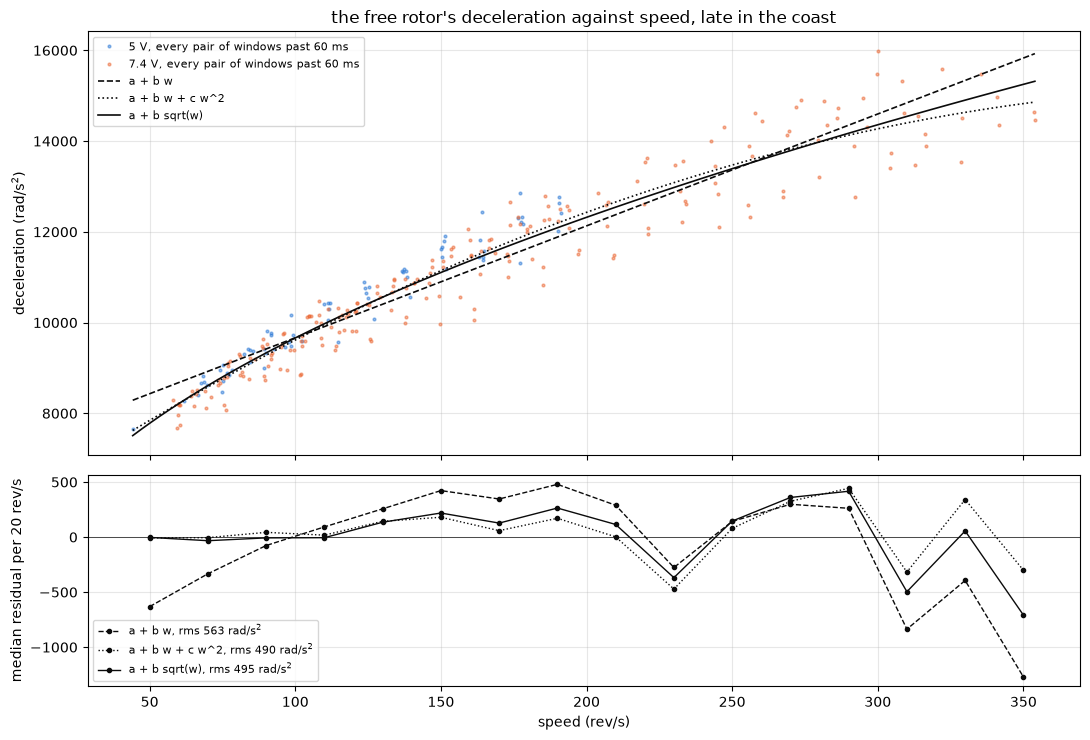

a + b w: 7199 +/- 77, 3.925 +/- 0.072
a + b w + c w^2: 5830 +/- 1.6e+02, 6.799 +/- 0.31, -0.001232 +/- 0.00013
a + b sqrt(w): 3242 +/- 1.3e+02, 256.1 +/- 4.1
5 V: 72 pairs from 44 to 191 rev/s, median +2.32 % from the curve
7.4 V: 218 pairs from 58 to 354 rev/s, median -0.08 % from the curve
the line a + b w as a constant and a viscous term: Coulomb 7199 rad/s^2, time constant 255 ms; the sqrt curve's constant 3242 rad/s^2 is 34 % of the drag at 100 rev/s and 23 % at 300 rev/s


In [11]:
LATE_S = 0.06                                                             # s past the cut, where the coast's drag has relaxed
sub = DEC[DEC["rev_s"] > FLOOR_REV_S]
late = sub[sub["t"] > LATE_S]
DRAG_FORMS = {"a + b w": (lambda w, a, b: a + b * w, [6000, 5]),
              "a + b w + c w^2": (lambda w, a, b, c: a + b * w + c * w ** 2, [6000, 5, 0]),
              "a + b sqrt(w)": (lambda w, a, b: a + b * np.sqrt(w), [3000, 200])}
DFIT = {}
for name, (f, p0) in DRAG_FORMS.items():
    p, cov = curve_fit(f, late["w"], late["alpha"], p0=p0, maxfev=20000)
    DFIT[name] = (p, np.sqrt(np.diag(cov)))
fig, ax = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for v in LEVELS:
    h = late[late["level"] == v]
    ax[0].plot(h["rev_s"], h["alpha"], ".", ms=4, color=COLOR[v], alpha=0.5, label=f"{v:g} V, every pair of windows past {LATE_S * 1e3:.0f} ms")
x = np.linspace(late["w"].min(), late["w"].max(), 100)
lbin = (late["rev_s"] // 20) * 20 + 10
for (name, (f, _)), ls in zip(DRAG_FORMS.items(), ["--", ":", "-"]):
    p = DFIT[name][0]
    ax[0].plot(x / (2 * np.pi), f(x, *p), ls, color=INK, lw=1.2, label=name)
    r = (late["alpha"] - f(late["w"], *p)).groupby(lbin).median()
    ax[1].plot(r.index, r.values, ls, marker=".", color=INK, lw=1, label=f"{name}, rms {np.sqrt(np.mean((late['alpha'] - f(late['w'], *p)) ** 2)):.0f} rad/s$^2$")
ax[0].set_ylabel("deceleration (rad/s$^2$)"); ax[0].set_title("the free rotor's deceleration against speed, late in the coast"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_ylabel("median residual per 20 rev/s"); ax[1].set_xlabel("speed (rev/s)"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
for name in DRAG_FORMS:
    p, se = DFIT[name]
    print(f"{name}: " + ", ".join(f"{a:.4g} +/- {b:.2g}" for a, b in zip(p, se)))
pa, _ = DFIT["a + b sqrt(w)"]
for v in LEVELS:
    h = late[late["level"] == v]
    print(f"{v:g} V: {len(h)} pairs from {h['rev_s'].min():.0f} to {h['rev_s'].max():.0f} rev/s, median {((h['alpha'] / (pa[0] + pa[1] * np.sqrt(h['w'])) - 1) * 100).median():+.2f} % from the curve")
p = DFIT["a + b w"][0]
print(f"the line a + b w as a constant and a viscous term: Coulomb {p[0]:.0f} rad/s^2, time constant {1 / p[1] * 1e3:.0f} ms; "
      f"the sqrt curve's constant {pa[0]:.0f} rad/s^2 is {pa[0] / (pa[0] + pa[1] * np.sqrt(2 * np.pi * 100)) * 100:.0f} % of the drag at 100 rev/s "
      f"and {pa[0] / (pa[0] + pa[1] * np.sqrt(2 * np.pi * 300)) * 100:.0f} % at 300 rev/s")

The free rotor's deceleration rises from about 7600 rad/s$^2$ at 44 rev/s to about 15000 at 350 rev/s, steep at the low end and flatter at the high end. A constant plus a viscous term, the straight line, misses at both ends. It sits 600 rad/s$^2$ over the points at 50 rev/s, 300 to 500 under them in the middle and 400 to 1300 over them above 300 rev/s. A constant plus a term in the square root of the speed follows the points from end to end with 495 rad/s$^2$ rms, and a line plus a square term does about as well with three terms. So the data chooses the square root, with moderate confidence. Its residual still swings by a few hundred rad/s$^2$ above 200 rev/s, 2 to 3 %, at about the scatter of the points. In that form the constant part is 3242 rad/s$^2$, 34 % of the drag at 100 rev/s and 23 % at 300 rev/s, and the rest grows with the square root of the speed. bemf-coast read the coasts as nearly straight lines and took that as mostly constant drag. On this fit the constant part would be the larger one only under about 25 rev/s, below the range of the data, and the part that grows with speed carries most of the drag everywhere the data reaches.

The square root is not a textbook drag law either. Friction that falls with speed as a lubricant film builds in the bearings, with a viscous term on top, would bend the curve this way, and so would brushes that ride more lightly as the commutator speeds up. Nothing here tells them apart.

The late decelerations at 5.0 V sit 2.3 % over the curve in the median and those at 7.4 V within 0.1 % of it. The 5.0 V cycles ran first, so this is the rail or the half hour between them, and a coast has no rail in it. So most likely the drag fell by about 2 % over the capture, a new motor running in, with moderate confidence. Against the 12 to 16 % more current the drive draws at 7.4 V that is small, and it goes the other way. The free rotor does not have more drag after a 7.4 V spin.

### The drag just after the cut

Every deceleration up to 354 rev/s over the late curve at the same speed, against the time from the cut, with the median per time bin. Beside it, the band from 80 to 110 rev/s in the cycles either side of the change of level. The 60 % coasts at 5.0 V pass through it late in their coast and the 15 % coasts at 7.4 V early in theirs, and the two ran one after the other. The thing to see is whether the drag at a given speed depends on how long ago the drive stopped.

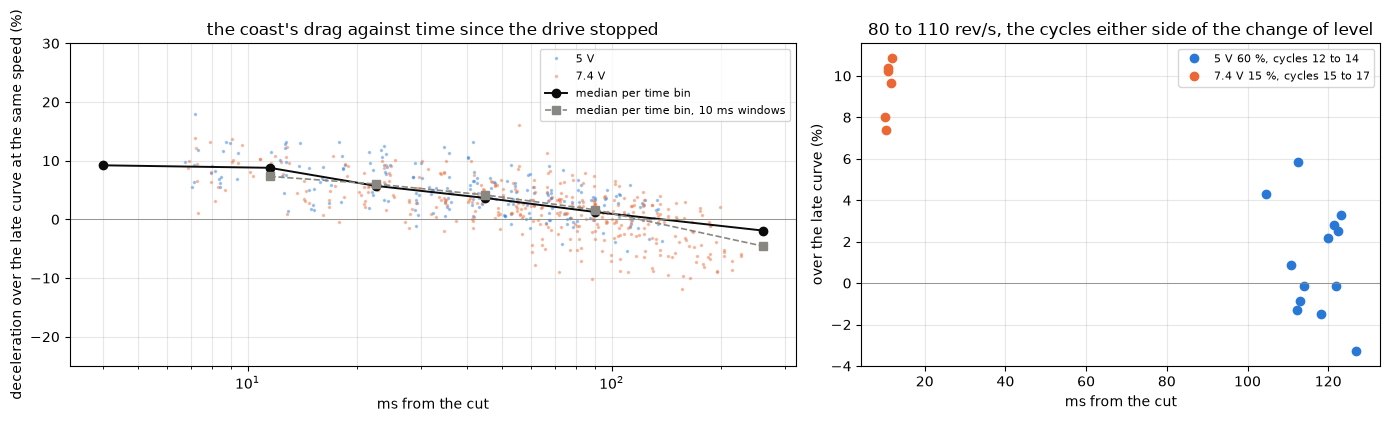

with 10 ms windows, median over the late curve per bin of time from the cut (%): {'(8, 15]': 7.3, '(15, 30]': 6.0, '(30, 60]': 4.2, '(60, 120]': 1.6, '(120, 400]': -4.6} | windows per bin: [37, 38, 72, 125, 39]
median over the late curve per bin of time from the cut (%): {'(0, 8]': 9.2, '(8, 15]': 8.8, '(15, 30]': 5.7, '(30, 60]': 3.6, '(60, 120]': 1.3, '(120, 400]': -1.9} | windows per bin: [18, 51, 90, 144, 201, 89]
the same per level (%): {'5 V': {'(0, 8]': 9.2, '(8, 15]': 8.8, '(15, 30]': 7.1, '(30, 60]': 4.5, '(60, 120]': 2.5, '(120, 400]': 1.5}, '7.4 V': {'(0, 8]': 9.1, '(8, 15]': 8.8, '(15, 30]': 5.2, '(30, 60]': 3.2, '(60, 120]': 1.0, '(120, 400]': -3.0}}
  80 to 110 rev/s, 5 V 60 %: 118 ms from the cut, +0.9 % over the late curve, 13 windows
  80 to 110 rev/s, 7.4 V 15 %: 11 ms from the cut, +10.0 % over the late curve, 6 windows


In [12]:
fa = DRAG_FORMS["a + b sqrt(w)"][0]
rel = sub[sub["w"] <= late["w"].max()].copy()                              # the speeds the late curve covers
rel["dev_pct"] = (rel["alpha"] / fa(rel["w"], *pa) - 1) * 100
rel["tbin"] = pd.cut(rel["t"] * 1e3, [0, 8, 15, 30, 60, 120, 400])
med = rel.groupby("tbin", observed=True)["dev_pct"].agg(["median", "count"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
for v in LEVELS:
    h = rel[rel["level"] == v]
    ax[0].plot(h["t"] * 1e3, h["dev_pct"], ".", ms=3, color=COLOR[v], alpha=0.35, label=f"{v:g} V")
mids = [iv.mid for iv in med.index]
ax[0].plot(mids, med["median"], "o-", color=INK, lw=1.4, label="median per time bin")
ax[0].axhline(0, color=MUTED, lw=0.6); ax[0].set_xscale("log"); ax[0].set_ylim(-25, 30)
ax[0].set_xlabel("ms from the cut"); ax[0].set_ylabel("deceleration over the late curve at the same speed (%)")
ax[0].set_title("the coast's drag against time since the drive stopped"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, which="both")
# the cycles either side of the change of level: 5.0 V at 60 % ran just before 7.4 V at 15 %, and both pass 80 to 110 rev/s
band = rel[(rel["rev_s"] > 80) & (rel["rev_s"] < 110)]
pairs_ = band[((band["level"] == 5.0) & (band["duty"] == 60)) | ((band["level"] == 7.4) & (band["duty"] == 15))]
for (v, du), h in pairs_.groupby(["level", "duty"]):
    ax[1].plot(h["t"] * 1e3, h["dev_pct"], MARK[1], color=COLOR[v], label=f"{v:g} V {du} %, cycles {h['k'].min()} to {h['k'].max()}")
ax[1].axhline(0, color=MUTED, lw=0.6); ax[1].set_xlabel("ms from the cut"); ax[1].set_ylabel("over the late curve (%)")
ax[1].set_title("80 to 110 rev/s, the cycles either side of the change of level"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
# the same read with windows twice as long, 10 ms of whole cycles: a longer window averages the first milliseconds in with the next ones
rows2 = []
for _, C in cycles.iterrows():
    df, meta = tel.load(cycle_folder(C["k"]), BOARD)
    rest = tel.baseline(df)
    zero_e = (rest["vmotor_a"] - rest["vmotor_b"]).median()
    for d, sp, co in pairs(df):
        s = SPIN[(SPIN["k"] == C["k"]) & (SPIN["dir"] == d)].iloc[0]
        z = cut_row(co)
        e_read = (((co["vmotor_a"] - co["vmotor_b"]) * d).to_numpy(float)[z:] - zero_e) * V_PER_COUNT
        e = bridge(e_read, open_rows(e_read))
        smooth = np.convolve(e, np.ones(NBH) / NBH, mode="same")
        stop = COAST_FROM + np.flatnonzero(smooth[COAST_FROM:] < TURN_V)[0]
        for i0, i1, f, n in walk(e, COAST_FROM, s["spin_speed_rev_s"] * N_R * 0.95, 2 * WIN_MS, FLOOR_REV_S, stop):
            rows2.append({"k": int(C["k"]), "level": float(C["volts_set"]), "duty": int(C["duty_pct"]), "dir": d, "t0": i0 / FS, "t1": i1 / FS, "w": 2 * np.pi * f / N_R, "cycles": n})
DEC2 = slopes(pd.DataFrame(rows2), "alpha")
DEC2["rev_s"] = DEC2["w"] / (2 * np.pi)
rel2 = DEC2[(DEC2["rev_s"] > FLOOR_REV_S) & (DEC2["w"] <= late["w"].max())].copy()
rel2["dev_pct"] = (rel2["alpha"] / fa(rel2["w"], *pa) - 1) * 100
rel2["tbin"] = pd.cut(rel2["t"] * 1e3, [0, 8, 15, 30, 60, 120, 400])
med2 = rel2.groupby("tbin", observed=True)["dev_pct"].agg(["median", "count"])
ax[0].plot([iv.mid for iv in med2.index], med2["median"], "s--", color=MUTED, lw=1.2, label="median per time bin, 10 ms windows")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
EARLY_LO, EARLY_HI = float(min(med["median"].iloc[0], med2["median"].iloc[0])), float(max(med["median"].iloc[0], med2["median"].iloc[0]))
print("with 10 ms windows, median over the late curve per bin of time from the cut (%):", {str(i): round(m, 1) for i, m in med2["median"].items()},
      "| windows per bin:", med2["count"].tolist())
print("median over the late curve per bin of time from the cut (%):", {str(i): round(m, 1) for i, m in med["median"].items()},
      "| windows per bin:", med["count"].tolist())
print("the same per level (%):", {f"{v:g} V": {str(i): round(m, 1) for i, m in rel[rel["level"] == v].groupby("tbin", observed=True)["dev_pct"].median().items()} for v in LEVELS})
for (v, du), h in pairs_.groupby(["level", "duty"]):
    print(f"  80 to 110 rev/s, {v:g} V {du} %: {h['t'].median() * 1e3:.0f} ms from the cut, {h['dev_pct'].median():+.1f} % over the late curve, {len(h)} windows")

It does, by an amount that depends on how the first milliseconds are read. With the 5 ms windows the rotor decelerates about 9 % harder in the first 15 ms after the cut than late in a coast at the same speed, 6 % harder at 15 to 30 ms, 4 % at 30 to 60 ms and 1 % at 60 to 120 ms. Windows twice as long, 10 ms of whole cycles, average the first milliseconds in with the next ones, reach no pair before 8 ms, and read 7 % at 8 to 15 ms, the gray squares. The windows past 60 ms set the curve, so the last two bins sit near zero on their own account, and the 120 to 400 ms bin at -1.9 % says the drag may still be falling then. The obvious confound is the order of the capture, since within each level the slow coasts, which pass any speed early in their coast, ran before the fast ones. The right panel takes that out. Cycles 12 to 14 and 15 to 17 ran one after the other, and at the same 80 to 110 rev/s the coasts 11 ms past their cut read +10 % and those 118 ms past theirs +0.9 %. So an excess just after the cut is likely; its size in the first 15 ms is 7 to 9 % by the window that reads it, and the first millisecond, where it would be largest, is not read at all. Its cause is open.

The early excess is the same at both levels in the first 15 ms, whichever window reads it. The drive's extra current at 7.4 V has no counterpart here, so whatever makes the 7.4 V spins draw more is most likely not this, or not only this.

This matters for the inertia. The drag the spin's current holds is the drag under drive, and the coast shows the drag closest to it only in its first milliseconds. So each spin is paired with its coast's deceleration at the cut and not with the late curve at the spin's speed. It also means the deceleration at the cut is the end of a curve that changes fast, and the drag in the first millisecond after the cut is not seen at all.

### The plan's route, spin by spin

Each spin's $K_t I_0$ over its coast's deceleration at the cut, against speed, with the deceleration itself beside it. If the drag under drive were the coast's drag at the cut, every spin would give the same $J$. The thing to see is whether the right panel is flat.

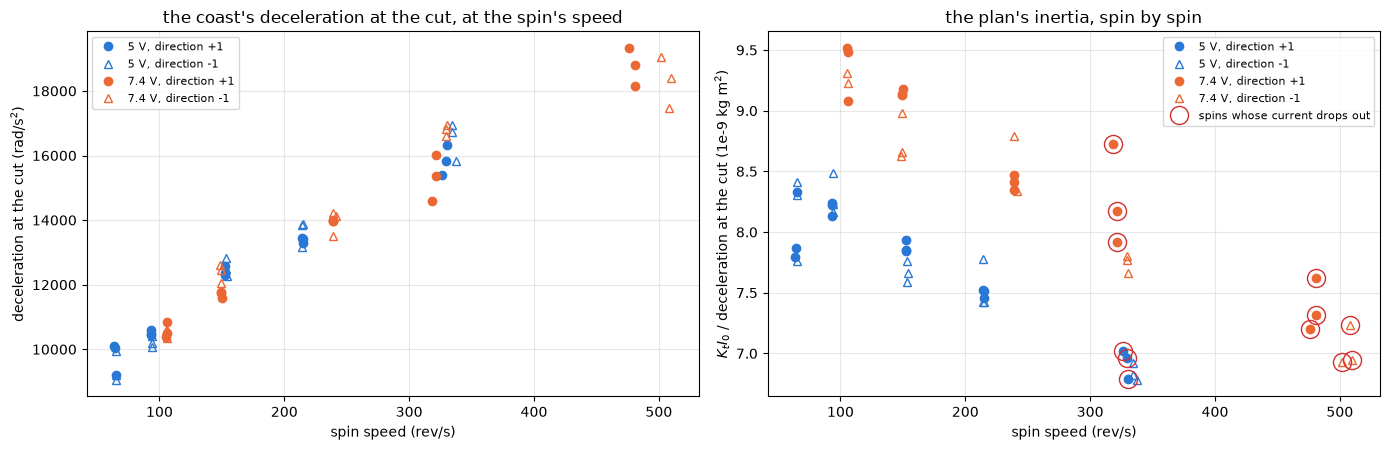

5 V: J by the ratio per rung [8.08, 8.25, 7.77, 7.52, 6.88] at [65, 94, 153, 215, 332] rev/s, spread within a rung [3.7, 1.5, 1.7, 1.8, 1.5] %; the open bridge's zero moves it -0.9 %
7.4 V: J by the ratio per rung [9.35, 8.95, 8.45, 8.01, 7.21] at [106, 149, 239, 325, 493] rev/s, spread within a rung [1.9, 2.8, 2.0, 4.9, 3.6] %; the open bridge's zero moves it -3.4 %
over every spin: 6.78 to 9.52, a line against speed -4.5 % of the mean per 100 rev/s (6 standard errors from flat)
near 150 rev/s, 5.0 V at 30 % against 7.4 V at 20 %: 7.77 and 8.95, the higher rail +15.2 %


In [13]:
CUT["j_ratio"] = KT * CUT["i0"] / CUT["alpha_cut"]                      # the plan's inertia: drive torque over deceleration at the cut
CUT["j_ratio_oz"] = KT * CUT["i0_oz"] / CUT["alpha_cut"]
CUT["opens"] = CUT["spin_open_per_s"] > 0
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for v in LEVELS:
    for d in (1, -1):
        h = CUT[(CUT["level"] == v) & (CUT["dir"] == d)]
        kw = dict(ls="none", marker=MARK[d], ms=6, color=COLOR[v], mfc=COLOR[v] if d == 1 else "none", label=f"{v:g} V, direction {d:+d}")
        ax[0].plot(h["spin_speed_rev_s"], h["alpha_cut"], **kw)
        ax[1].plot(h["spin_speed_rev_s"], h["j_ratio"] * 1e9, **kw)
op = CUT[CUT["opens"]]
ax[1].plot(op["spin_speed_rev_s"], op["j_ratio"] * 1e9, "o", ms=13, mfc="none", color=RED, label="spins whose current drops out")
ax[0].set_ylabel("deceleration at the cut (rad/s$^2$)"); ax[0].set_title("the coast's deceleration at the cut, at the spin's speed")
ax[1].set_ylabel("$K_t I_0$ / deceleration at the cut (1e-9 kg m$^2$)"); ax[1].set_title("the plan's inertia, spin by spin")
for a in ax:
    a.set_xlabel("spin speed (rev/s)"); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
JR = CUT.groupby(["level", "duty"]).agg(rev_s=("spin_speed_rev_s", "mean"), j=("j_ratio", "mean"), j_sd=("j_ratio", "std"), j_oz=("j_ratio_oz", "mean"), a=("alpha_cut", "mean")).reset_index()
for v in LEVELS:
    r = JR[JR["level"] == v]
    print(f"{v:g} V: J by the ratio per rung {np.round(r['j'].to_numpy() * 1e9, 2).tolist()} at {np.round(r['rev_s'].to_numpy()).astype(int).tolist()} rev/s, "
          f"spread within a rung {np.round(r['j_sd'] / r['j'] * 100, 1).tolist()} %; the open bridge's zero moves it {((r['j_oz'] / r['j']).mean() - 1) * 100:+.1f} %")
JL = laps.line(CUT["spin_speed_rev_s"], CUT["j_ratio"])
print(f"over every spin: {CUT['j_ratio'].min() * 1e9:.2f} to {CUT['j_ratio'].max() * 1e9:.2f}, a line against speed {JL['slope'] / CUT['j_ratio'].mean() * 100 * 100:+.1f} % of the mean per 100 rev/s "
      f"({abs(JL['slope'] / JL['slope_se']):.0f} standard errors from flat)")
d5 = CUT[(CUT["level"] == 5.0) & (CUT["duty"] == 30)]["j_ratio"].mean(); d7 = CUT[(CUT["level"] == 7.4) & (CUT["duty"] == 20)]["j_ratio"].mean()
print(f"near 150 rev/s, 5.0 V at 30 % against 7.4 V at 20 %: {d5 * 1e9:.2f} and {d7 * 1e9:.2f}, the higher rail {(d7 / d5 - 1) * 100:+.1f} %")

It is not. The ratio falls from about 8.2 at the slowest rungs to 6.9 across the 5.0 V rungs and from 9.4 to 7.2 across the 7.4 V rungs, in units of $10^{-9}$ kg m$^2$, about 4.5 % of its mean per 100 rev/s and six standard errors from flat. At the same speed, near 150 rev/s, the 7.4 V rungs read 15 % over the 5.0 V ones. A rotor has one inertia, so the ratio is not an inertia. The deceleration at the cut is the same at both levels at the same speed to within about 4 %, the left panel, while the current is not. So the drive's current at a given speed carries something the coast's deceleration does not, and more of it at 7.4 V. The open bridge's zero lowers the ratio by 0.9 % at 5.0 V and 3.4 % at 7.4 V, which closes about a sixth of the gap between the levels. Within a rung the six spins spread 1.5 to 4.9 %.

### Torque against deceleration

The same spins as the drive's torque $K_t I_0$ against the coast's deceleration at the cut, with a line per level and a line through the origin at the median ratio. The thing to see is whether a line with an intercept fits each level, and where the lines meet zero deceleration.

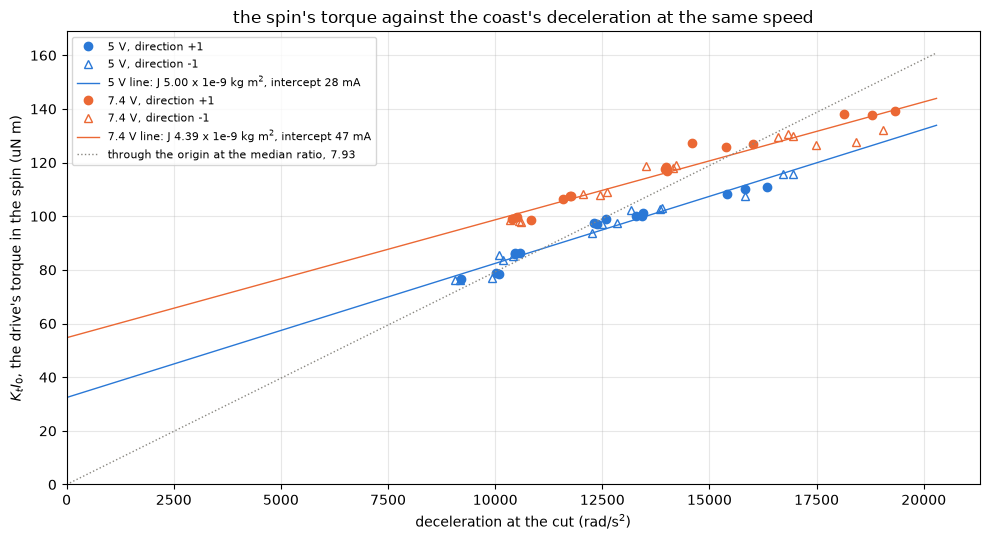

5 V direction +1: J 5.00 +/- 0.31 x 1e-9 kg m^2, intercept +27.8 +/- 3.4 mA, rms 2.10 mA over 15 spins
5 V direction -1: J 5.00 +/- 0.26 x 1e-9 kg m^2, intercept +27.7 +/- 2.8 mA, rms 2.04 mA over 15 spins
5 V both: J 5.00 +/- 0.19 x 1e-9 kg m^2, intercept +27.8 +/- 2.1 mA, rms 2.07 mA over 30 spins
5 V both, open-bridge zero: J 4.96 +/- 0.19 x 1e-9 kg m^2, intercept +27.4 +/- 2.1 mA, rms 2.07 mA over 30 spins
7.4 V direction +1: J 4.72 +/- 0.24 x 1e-9 kg m^2, intercept +43.9 +/- 3.0 mA, rms 2.17 mA over 15 spins
7.4 V direction -1: J 4.10 +/- 0.31 x 1e-9 kg m^2, intercept +49.4 +/- 3.9 mA, rms 2.77 mA over 15 spins
7.4 V both: J 4.39 +/- 0.21 x 1e-9 kg m^2, intercept +46.8 +/- 2.7 mA, rms 2.79 mA over 30 spins
7.4 V both, open-bridge zero: J 4.39 +/- 0.22 x 1e-9 kg m^2, intercept +43.5 +/- 2.7 mA, rms 2.84 mA over 30 spins
one J for both levels (in-drive offset): 4.64 +/- 0.15 x 1e-9 kg m^2, intercepts 5 V +31.6 mA, 7.4 V +43.9 mA, rms 2.55 mA
one J for both levels (open-bridge zero):

In [14]:
def line_fit(g, col):
    # drive torque on deceleration at the cut: slope J, intercept a torque the coast does not show, given as a current
    l = laps.line(g["alpha_cut"], KT * g[col])
    return {"j": l["slope"], "j_se": l["slope_se"], "i_x": l["intercept"] / KT, "i_x_se": l["intercept_se"] / KT, "rms": l["rms"] / KT, "n": l["n"]}

def common_fit(g, col):
    # one J for both levels and one intercept per level, by least squares
    X = np.c_[g["alpha_cut"], (g["level"] == LEVELS[0]).astype(float), (g["level"] == LEVELS[1]).astype(float)]
    b, *_ = np.linalg.lstsq(X, KT * g[col], rcond=None)
    r = KT * g[col] - X @ b
    cov = np.linalg.inv(X.T @ X) * (r @ r) / (len(g) - 3)
    return {"j": b[0], "j_se": np.sqrt(cov[0, 0]), "i_x": {v: b[1 + j] / KT for j, v in enumerate(LEVELS)}, "rms": float(np.sqrt(np.mean(r ** 2)) / KT)}

LINE = {(v, d, col): line_fit(CUT[(CUT["level"] == v) & ((CUT["dir"] == d) if d else True)], col) for v in LEVELS for d in (1, -1, None) for col in ("i0", "i0_oz")}
COMMON = {col: common_fit(CUT, col) for col in ("i0", "i0_oz")}
COMMON_CLEAN = common_fit(CUT[~CUT["opens"]], "i0")                      # the same without the spins whose current drops out
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.linspace(0, CUT["alpha_cut"].max() * 1.05, 10)
for v in LEVELS:
    for d in (1, -1):
        h = CUT[(CUT["level"] == v) & (CUT["dir"] == d)]
        ax.plot(h["alpha_cut"], KT * h["i0"] * 1e6, MARK[d], ms=6, color=COLOR[v], mfc=COLOR[v] if d == 1 else "none", label=f"{v:g} V, direction {d:+d}")
    L = LINE[(v, None, "i0")]
    ax.plot(x, (L["j"] * x + KT * L["i_x"]) * 1e6, "-", lw=1, color=COLOR[v], label=f"{v:g} V line: J {L['j'] * 1e9:.2f} x 1e-9 kg m$^2$, intercept {L['i_x'] * 1e3:.0f} mA")
ax.plot(x, CUT["j_ratio"].median() * x * 1e6, ":", color=MUTED, lw=1, label=f"through the origin at the median ratio, {CUT['j_ratio'].median() * 1e9:.2f}")
ax.set_xlim(0); ax.set_ylim(0)
ax.set_xlabel("deceleration at the cut (rad/s$^2$)"); ax.set_ylabel("$K_t I_0$, the drive's torque in the spin (uN m)")
ax.set_title("the spin's torque against the coast's deceleration at the same speed"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
for (v, d, col), L in LINE.items():
    if col == "i0" or d is None:
        print(f"{v:g} V {'both' if d is None else f'direction {d:+d}'}{', open-bridge zero' if col == 'i0_oz' else ''}: J {L['j'] * 1e9:.2f} +/- {L['j_se'] * 1e9:.2f} x 1e-9 kg m^2, "
              f"intercept {L['i_x'] * 1e3:+.1f} +/- {L['i_x_se'] * 1e3:.1f} mA, rms {L['rms'] * 1e3:.2f} mA over {L['n']} spins")
def intercepts(C_):
    return ", ".join(f"{v:g} V {C_['i_x'][v] * 1e3:+.1f} mA" for v in LEVELS)
for col, C_ in COMMON.items():
    print(f"one J for both levels ({'open-bridge zero' if col == 'i0_oz' else 'in-drive offset'}): {C_['j'] * 1e9:.2f} +/- {C_['j_se'] * 1e9:.2f} x 1e-9 kg m^2, "
          f"intercepts {intercepts(C_)}, rms {C_['rms'] * 1e3:.2f} mA")
print(f"the same without the {int(CUT['opens'].sum())} spins whose current drops out: J {COMMON_CLEAN['j'] * 1e9:.2f} +/- {COMMON_CLEAN['j_se'] * 1e9:.2f}, "
      f"intercepts {intercepts(COMMON_CLEAN)}")

A straight line fits each level with 2.1 mA rms at 5.0 V and 2.8 mA at 7.4 V. At 5.0 V its slope is $J$ = 5.00 +/- 0.19 with an intercept of 28 +/- 2 mA, the same in both directions. At 7.4 V it is 4.39 +/- 0.21 with 47 +/- 3 mA, and the two directions part, 4.72 and 4.10. One $J$ for both levels, with an intercept per level, gives 4.64 +/- 0.15 with 32 and 44 mA. Leaving out the twelve spins whose current drops out moves it to 5.12 +/- 0.15 with 27 and 39 mA, since the 60 % rungs at 7.4 V sit at the top of the line and pull its slope. The open bridge's zero moves the slope by under 1 % and the intercepts by 0.6 and 3 mA, as a constant offset in the current should.

Read this way, the drive draws a current that does not change with speed, about 30 mA at 5.0 V and 45 mA at 7.4 V, on top of a part that follows the coast's drag at the cut through one $J$ of 4.6 to 5.1. That is 40 to 50 % of the no-load current. A line is one reading of these points and not proven by them, since a part that changes slowly with speed would fit as well over this range. The candidates for such a part, with what this data says about each.

- The current reads high under a switching drive, by an amount that grows with the rail. The open bridge's zero does rise with the rail, by 3 counts from 5.0 to 7.4 V, but a reading 30 to 50 counts high is ten times anything measured so far.
- A drag that only the drive has and that goes almost at once when the drive stops, brush friction that depends on the current through the contact, or a drag from the winding's own field on the rotor's iron. The coast's extra drag in its first milliseconds may be the tail of something like this, but it is about 9 % of the drag, where the line's intercept is half to all of the coast's drag at the cut, and it is the same at both levels.
- A braking current in the coast through a path that leaves the shunt out, which would make the coast decelerate harder the faster it turns. bemf-coast bounds a current through the shunt at 1.8 mA, and the other paths run through the dividers' kilohms. Unlikely.

The Open questions carry the experiments that tell these apart.

### The spin-up

The inertia from the start of each spin, window by window, against how far the window's current sits over the settled curve at its speed. Beside it, once the speed has settled, the current over the settled curve against the time into the spin. The thing to see is whether the ratio holds steady where the current over the curve is large, and how long the drive takes to come down to its settled current.

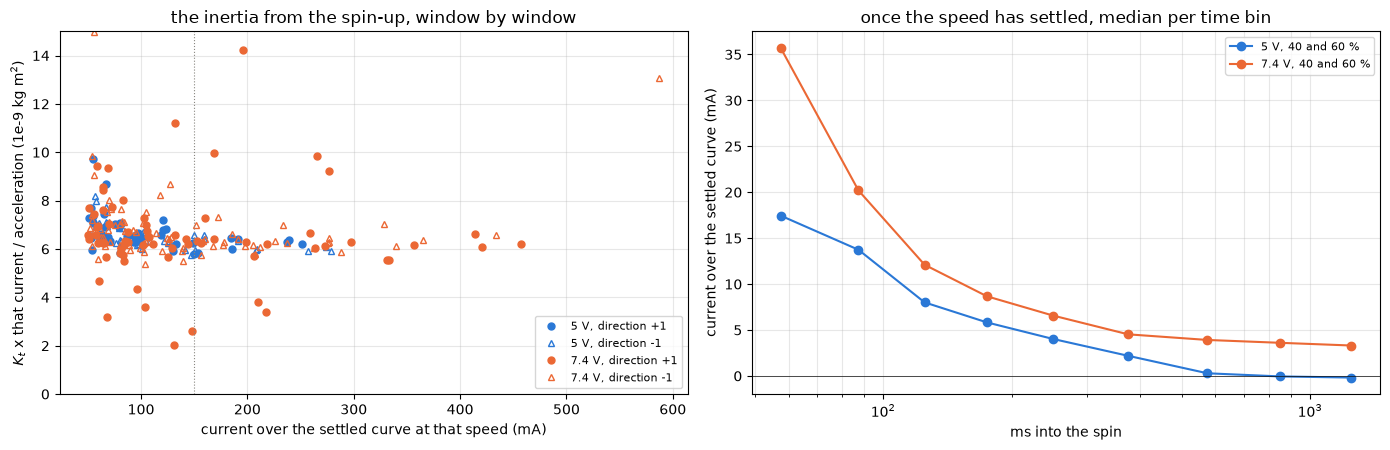

start of the spin-up, current 150 mA and more over the curve: 70 windows from 8 to 35 ms, 118 to 411 rev/s; J 6.30 x 1e-9 kg m^2 in the median (5.96 to 7.04)
  per level and duty: 5 V 40 % 5.96 (1), 5 V 60 % 6.26 (16), 7.4 V 30 % 6.14 (4), 7.4 V 40 % 6.27 (18), 7.4 V 60 % 6.42 (31)
  per direction: -1 6.29 (38), +1 6.30 (32); without the rungs whose current drops out 6.20 (22); the windows' current over the curve 222 mA in the median
a line through every window with 50 mA and more over the curve: J 5.33 +/- 0.25, intercept +27.0 +/- 6.3 mA; per level 5 V 5.64 +/- 0.30 with +16.2 mA, 7.4 V 5.22 +/- 0.34 with +32.5 mA
per direction +1 4.57 +/- 0.36 with +39.4 mA, -1 6.46 +/- 0.34 with +7.2 mA; without the rungs whose current drops out 5.85 +/- 0.19 with +10.7 mA
settled speed, 5 V, current over the curve per bin of ms into the spin (mA): {'(40, 75]': 17.5, '(75, 100]': 13.7, '(100, 150]': 8.0, '(150, 200]': 5.8, '(200, 300]': 4.0, '(300, 450]': 2.2, '(450, 700]': 0.3, '(700, 1000]': -0.1

In [15]:
ACC["i0_curve"] = [i0_log(w, *I0FIT[v][0]) for w, v in zip(ACC["w"], ACC["level"])]   # the settled curve of the level at that speed
ACC["excess"] = ACC["i"] - ACC["i0_curve"]                                 # the current beyond what the settled spin draws at that speed
ACC["j"] = KT * ACC["excess"] / ACC["acc"]
EXCESS_MIN = 0.15                                                          # A, the start of the spin-up, where the drive's torque is two to four times the drag
early = ACC[(ACC["excess"] >= EXCESS_MIN) & (ACC["acc"] > 10_000)]
fit_rows = ACC[(ACC["excess"] >= 0.05) & (ACC["acc"] > 3000)]
UPL = laps.line(fit_rows["acc"], KT * fit_rows["excess"])
UPL_LEVEL = {v: laps.line(fit_rows[fit_rows["level"] == v]["acc"], KT * fit_rows[fit_rows["level"] == v]["excess"]) for v in LEVELS}
UPL_DIR = {d: laps.line(fit_rows[fit_rows["dir"] == d]["acc"], KT * fit_rows[fit_rows["dir"] == d]["excess"]) for d in (1, -1)}
clean = fit_rows.merge(OPEN_RUNGS, how="left", indicator=True).query("_merge == 'left_only'")   # without the rungs whose current drops out
UPL_CLEAN = laps.line(clean["acc"], KT * clean["excess"])
flat = ACC[(ACC["acc"].abs() < 2000) & (ACC["duty"] >= 40)].copy()          # windows where the speed has about settled
flat["tbin"] = pd.cut(flat["t"] * 1e3, [40, 75, 100, 150, 200, 300, 450, 700, 1000, 1500])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for v in LEVELS:
    for d in (1, -1):
        h = fit_rows[(fit_rows["level"] == v) & (fit_rows["dir"] == d)]
        ax[0].plot(h["excess"] * 1e3, h["j"] * 1e9, MARK[d], ms=5, color=COLOR[v], mfc=COLOR[v] if d == 1 else "none", label=f"{v:g} V, direction {d:+d}")
ax[0].axvline(EXCESS_MIN * 1e3, color=MUTED, lw=0.8, ls=":")
ax[0].set_xlabel("current over the settled curve at that speed (mA)"); ax[0].set_ylabel("$K_t$ x that current / acceleration (1e-9 kg m$^2$)")
ax[0].set_title("the inertia from the spin-up, window by window"); ax[0].set_ylim(0, 15); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
for v in LEVELS:
    m = flat[flat["level"] == v].groupby("tbin", observed=True)["excess"].median()
    ax[1].plot([iv.mid for iv in m.index], m.values * 1e3, "o-", color=COLOR[v], label=f"{v:g} V, 40 and 60 %")
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_xscale("log")
ax[1].set_xlabel("ms into the spin"); ax[1].set_ylabel("current over the settled curve (mA)")
ax[1].set_title("once the speed has settled, median per time bin"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()
J_UP = early["j"].median()
print(f"start of the spin-up, current {EXCESS_MIN * 1e3:.0f} mA and more over the curve: {len(early)} windows from {early['t'].min() * 1e3:.0f} to {early['t'].max() * 1e3:.0f} ms, "
      f"{early['rev_s'].min():.0f} to {early['rev_s'].max():.0f} rev/s; J {J_UP * 1e9:.2f} x 1e-9 kg m^2 in the median ({early['j'].quantile(0.16) * 1e9:.2f} to {early['j'].quantile(0.84) * 1e9:.2f})")
early_clean = early.merge(OPEN_RUNGS, how="left", indicator=True).query("_merge == 'left_only'")
print("  per level and duty: " + ", ".join(f"{v:g} V {du} % {h['j'].median() * 1e9:.2f} ({len(h)})" for (v, du), h in early.groupby(["level", "duty"])))
print("  per direction: " + ", ".join(f"{d:+d} {h['j'].median() * 1e9:.2f} ({len(h)})" for d, h in early.groupby("dir"))
      + f"; without the rungs whose current drops out {early_clean['j'].median() * 1e9:.2f} ({len(early_clean)}); "
      f"the windows' current over the curve {early['excess'].median() * 1e3:.0f} mA in the median")
print(f"a line through every window with 50 mA and more over the curve: J {UPL['slope'] * 1e9:.2f} +/- {UPL['slope_se'] * 1e9:.2f}, "
      f"intercept {UPL['intercept'] / KT * 1e3:+.1f} +/- {UPL['intercept_se'] / KT * 1e3:.1f} mA; per level "
      + ", ".join(f"{v:g} V {L['slope'] * 1e9:.2f} +/- {L['slope_se'] * 1e9:.2f} with {L['intercept'] / KT * 1e3:+.1f} mA" for v, L in UPL_LEVEL.items()))
print("per direction " + ", ".join(f"{d:+d} {L['slope'] * 1e9:.2f} +/- {L['slope_se'] * 1e9:.2f} with {L['intercept'] / KT * 1e3:+.1f} mA" for d, L in UPL_DIR.items())
      + f"; without the rungs whose current drops out {UPL_CLEAN['slope'] * 1e9:.2f} +/- {UPL_CLEAN['slope_se'] * 1e9:.2f} with {UPL_CLEAN['intercept'] / KT * 1e3:+.1f} mA")
for v in LEVELS:
    print(f"settled speed, {v:g} V, current over the curve per bin of ms into the spin (mA):", {str(i): round(x * 1e3, 1) for i, x in flat[flat['level'] == v].groupby('tbin', observed=True)['excess'].median().items()})

Where the current runs 150 mA or more over the settled curve, the first 8 to 35 ms of the 30 to 60 % spins, the ratio holds at 6.30 in the median, 5.96 to 7.04 from the 16th to the 84th percentile. It is the same in both directions, 6.29 and 6.30, and 6.1 to 6.4 at every level and duty with more than one window. Leaving out the rungs whose current drops out moves it to 6.20. It needs no coast and no zero, since the zero cancels between a window's current and the settled curve.

As the current over the curve falls, the ratio climbs, to about 7 in the median at 50 to 100 mA, with a long tail upward. The right panel says why. Once the speed has settled the current still sits over the settled curve, by 17 mA at 40 to 75 ms at 5.0 V and 36 mA at 7.4 V, 8 and 12 mA at 100 to 150 ms, and it takes 300 to 700 ms to come within a few milliamps. This is the fast start of the slide bemf-coast saw, the current falling while the speed holds. So early in a run the drive holds a drag higher than its settled one, and the spin-up's ratio counts that extra drag as inertia. At the 222 mA over the curve of the median window used, an extra 20 to 40 mA reads $J$ 10 to 20 % high. So the 6.3 is most likely an upper end, with moderate confidence.

A line through the windows lets a constant extra current show as its intercept, and gives 5.33 +/- 0.25 with 27 mA. That line is not steady, though. It reads 4.57 in direction +1 and 6.46 in direction -1, and 5.85 without the rungs that drop out, since the extra drag fades over the same time the acceleration does, and a line does not tell the two apart.

### J by every route

Every route to the inertia on one axis, the lines black and the ratios gray, the working value dashed and the bracket the result file carries shaded. The thing to see is how far the routes spread and where they gather.

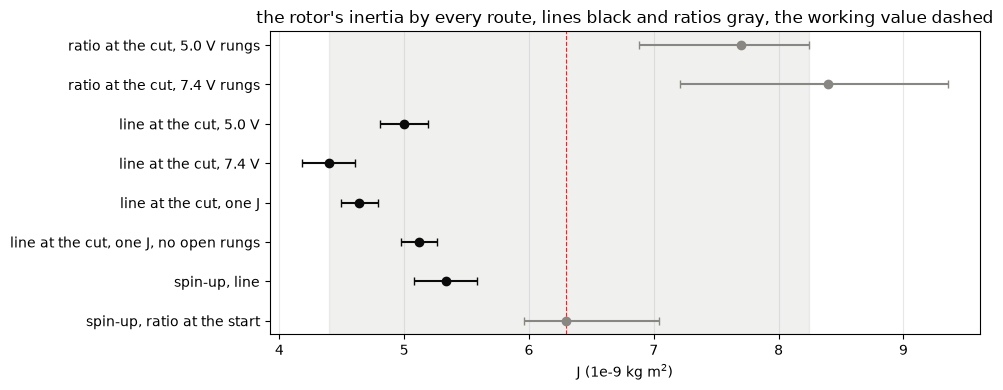

ratio at the cut, 5.0 V rungs   7.70  (6.88 to 8.25)
ratio at the cut, 7.4 V rungs   8.40  (7.21 to 9.35)
line at the cut, 5.0 V          5.00  (4.81 to 5.19)
line at the cut, 7.4 V          4.39  (4.18 to 4.61)
line at the cut, one J          4.64  (4.49 to 4.79)
line at the cut, one J, no open rungs  5.12  (4.98 to 5.27)
spin-up, line                   5.33  (5.08 to 5.59)
spin-up, ratio at the start     6.30  (5.96 to 7.04)


In [16]:
ROUTES = [  # (label, value, lo, hi) in kg m^2: the inertia by every route, with its spread
    ("ratio at the cut, 5.0 V rungs", *(lambda r: (r.mean(), r.min(), r.max()))(JR[JR["level"] == 5.0]["j"])),
    ("ratio at the cut, 7.4 V rungs", *(lambda r: (r.mean(), r.min(), r.max()))(JR[JR["level"] == 7.4]["j"])),
    ("line at the cut, 5.0 V", LINE[(5.0, None, "i0")]["j"], LINE[(5.0, None, "i0")]["j"] - LINE[(5.0, None, "i0")]["j_se"], LINE[(5.0, None, "i0")]["j"] + LINE[(5.0, None, "i0")]["j_se"]),
    ("line at the cut, 7.4 V", LINE[(7.4, None, "i0")]["j"], LINE[(7.4, None, "i0")]["j"] - LINE[(7.4, None, "i0")]["j_se"], LINE[(7.4, None, "i0")]["j"] + LINE[(7.4, None, "i0")]["j_se"]),
    ("line at the cut, one J", COMMON["i0"]["j"], COMMON["i0"]["j"] - COMMON["i0"]["j_se"], COMMON["i0"]["j"] + COMMON["i0"]["j_se"]),
    ("line at the cut, one J, no open rungs", COMMON_CLEAN["j"], COMMON_CLEAN["j"] - COMMON_CLEAN["j_se"], COMMON_CLEAN["j"] + COMMON_CLEAN["j_se"]),
    ("spin-up, line", UPL["slope"], UPL["slope"] - UPL["slope_se"], UPL["slope"] + UPL["slope_se"]),
    ("spin-up, ratio at the start", J_UP, early["j"].quantile(0.16), early["j"].quantile(0.84)),
]
fig, ax = plt.subplots(figsize=(10, 4))
for y, (label, v, lo, hi) in enumerate(ROUTES):
    ax.errorbar(v * 1e9, y, xerr=[[(v - lo) * 1e9], [(hi - v) * 1e9]], fmt="o", color=INK if "line" in label else MUTED, capsize=3)
ax.set_yticks(range(len(ROUTES))); ax.set_yticklabels([r[0] for r in ROUTES]); ax.invert_yaxis()
LINE_ROUTES = [r for r in ROUTES if "line" in r[0]]
J_LO, J_HI = min(r[1] for r in LINE_ROUTES), JR[JR["level"] == 5.0]["j"].max()   # the bracket: the lowest line route to the ratio at the cut at the slowest 5.0 V rung, which needs no drive-only current
ax.axvspan(J_LO * 1e9, J_HI * 1e9, color=MUTED, alpha=0.12)
ax.axvline(J_UP * 1e9, color=RED, lw=0.8, ls="--")
ax.set_xlabel("J (1e-9 kg m$^2$)"); ax.set_title("the rotor's inertia by every route, lines black and ratios gray, the working value dashed"); ax.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()
for label, v, lo, hi in ROUTES:
    print(f"{label:30s} {v * 1e9:5.2f}  ({lo * 1e9:.2f} to {hi * 1e9:.2f})")

The routes spread from 4.4 to 8.4 in units of $10^{-9}$ kg m$^2$. The ratio at the cut is an inertia only where nothing in the drive's current is torque-free, and at the slowest 5.0 V rungs, 65 to 94 rev/s, it reads 8.1 to 8.3 with no such current needed; whether the lines' intercept is a torque-free current in the drive or a drag the coast carries that the drive does not, this data does not say, and the two readings put $J$ at 5 and at 8. The routes that let such a current show run from 4.4 to 6.3. The lines, which let a current outside the inertia show as an intercept, gather at 4.4 to 5.3. The spin-up's ratio, which counts every such current as inertia, sits on top at 6.3. The result file carries 6.3 as the working value, since it is the one route that holds the same in both directions, at every level and with or without the open rungs, with a bracket from 4.4 to 8.2, the lowest line route to the ratio at the slowest rung. It is most likely high against the lines and low against the ratio. I would put the rotor's inertia between 5 and 8 x $10^{-9}$ kg m$^2$, with low confidence on where in that span. A coast with a known inertia added to the rotor needs no current at all and would settle it, and the Open questions carry it.

### The results file

The no-load current per level, duty and direction with its speed and spread, through both zeros. The log curve of the no-load current per level with its speed range, as the drag under drive, which is $K_t$ times it. The level gap at the same speed both ways. The free rotor's deceleration curve from the late coast with its range, and the early excess after the cut. The inertia, its working value with the bracket of the routes, every route on its own, the spin-up's ratio by level and direction and without the open rungs, the lines with the open bridge's zero and without the open rungs, and the intercepts as the drive's extra current per level. The ratio's trend with speed, the spin window's current drift, the early-run excess over time, and the check on the speed at the cut.

In [17]:
q = results.quantity

def qse(v, se, unit, scale=1.0):
    # value with +/- one standard error as the bounds
    return q(v * scale, (v - se) * scale, (v + se) * scale, unit)

i0_by_speed = [{"level_v": float(r["level"]), "duty_pct": int(r["duty"]), "direction": int(r["dir"]), "n": int(r["n"]),
                "speed_rev_s": qse(r["rev_s"], r["rev_sd"], "rev/s"), "current_a": qse(r["i0"], r["i0_sd"], "A"),
                "current_open_zero_a": q(r["i0_oz"], unit="A"), "drops_out_per_s": q(r["opens"], unit="1/s")} for _, r in RUNG.iterrows()]
drive = {}
for v in LEVELS:
    (a, b), (sa, sb), rms = I0FIT[v]
    g = SPIN[SPIN["level"] == v]
    drive[f"{v:g} V"] = {"form": "I0 = a + b ln(w / w_ref), w in rad/s, w_ref = 2 pi x 100 rad/s; drag torque = Kt x I0",
                         "a_a": qse(a, sa, "A"), "b_a": qse(b, sb, "A per unit of ln(w)"), "rms_a": q(rms, unit="A"),
                         "a_open_zero_a": q(FIT_OZ[v][0][0], unit="A"), "b_open_zero_a": q(FIT_OZ[v][0][1], unit="A per unit of ln(w)"),
                         "speed_range_rev_s": q(g["spin_speed_rev_s"].max(), g["spin_speed_rev_s"].min(), g["spin_speed_rev_s"].max(), "rev/s")}
pa, sa = DFIT["a + b sqrt(w)"]
j_value, j_lo, j_hi = J_UP, J_LO, J_HI
path = results.write("2-motor", "no-load-current", CAPTURE, pair=MOTOR.key,
    notes="read from the bemf-coast dataset and result, no capture of its own. The no-load current is bemf-coast's i_spin_a, the spin window's last 200 ms "
          "through current-scale with its in-drive offset, and i_spin_open_zero_a beside it; the speed is bemf-coast's count of the spin's current ripple. "
          "drive_drag_by_level is a + b ln(w / w_ref) fitted per level, valid over its speed range. The coast's speed is counted in windows of whole ripple "
          "cycles down every coast, no Ke involved; coast_decel_late_rad_s2 is a + b sqrt(w) through the decelerations more than 60 ms past the cut. "
          "alpha at the cut is a parabola in time through the ripple's crossings over the stretch where the speed falls 30 %, the speed at the cut pinned "
          "to the spin's count. j_kg_m2 is the spin-up route, the median of Kt (I - I0(w)) over the acceleration in the spin-up's windows with 150 mA and "
          "more over the settled curve of the level, both levels and directions; its bounds run from the lowest line route, which lets a torque-free current in the drive show, "
          "to the ratio at the cut at the slowest 5.0 V rung, which needs none, since the data does not say which reading is right; "
          "j_by_route carries each route; drive_excess_a_by_level is the intercept of Kt I0 on alpha at the cut with one J for both levels, current the "
          "spin draws that the coast's deceleration does not account for; spinup_excess_a is the spin-up line's intercept",
    ke_v_s_per_rad=BC["ke_v_s_per_rad"],
    kt_n_m_per_a=q(KT, BC["ke_v_s_per_rad"]["lo"], BC["ke_v_s_per_rad"]["hi"], "N m/A"),
    i0_by_speed=i0_by_speed,
    drive_drag_by_level=drive,
    level_gap_a=q(m7["gap"].mean() / 1e3, m7["gap"].min() / 1e3, m7["gap"].max() / 1e3, "A, 7.4 V over the 5.0 V curve at the same speed"),
    level_gap_open_zero_a=q(m7["gap_oz"].mean() / 1e3, m7["gap_oz"].min() / 1e3, m7["gap_oz"].max() / 1e3, "A"),
    coast_decel_late_rad_s2={"form": "alpha = a + b sqrt(w), w in rad/s", "a": qse(pa[0], sa[0], "rad/s^2"), "b": qse(pa[1], sa[1], "rad/s^2 per sqrt(rad/s)"),
                             "speed_range_rev_s": q(late["rev_s"].max(), late["rev_s"].min(), late["rev_s"].max(), "rev/s")},
    coast_relax_early_pct=q(med["median"].iloc[0], EARLY_LO, EARLY_HI, "% over the late curve in the first 8 ms, 5 ms windows; the bounds span the 5 and 10 ms windows"),
    j_kg_m2=q(j_value, j_lo, j_hi, "kg m^2"),
    j_by_route={label: q(v, lo, hi, "kg m^2") for label, v, lo, hi in ROUTES},
    j_spinup_ratio_by_level={f"{v:g} V": q(h["j"].median(), h["j"].quantile(0.16), h["j"].quantile(0.84), "kg m^2") for v, h in early.groupby("level")},
    j_spinup_ratio_by_direction={f"{d:+d}": q(h["j"].median(), h["j"].quantile(0.16), h["j"].quantile(0.84), "kg m^2") for d, h in early.groupby("dir")},
    j_spinup_ratio_without_open_rungs_kg_m2=q(early_clean["j"].median(), early_clean["j"].quantile(0.16), early_clean["j"].quantile(0.84), "kg m^2"),
    j_spinup_line_by_level={f"{v:g} V": qse(L["slope"], L["slope_se"], "kg m^2") for v, L in UPL_LEVEL.items()},
    j_spinup_line_by_direction={f"{d:+d}": qse(L["slope"], L["slope_se"], "kg m^2") for d, L in UPL_DIR.items()},
    j_spinup_line_without_open_rungs_kg_m2=qse(UPL_CLEAN["slope"], UPL_CLEAN["slope_se"], "kg m^2"),
    spinup_line_excess_a=qse(UPL["intercept"] / KT, UPL["intercept_se"] / KT, "A"),
    early_run_excess_a_by_level={f"{v:g} V": {f"{i.left:g} to {i.right:g} ms": q(x, unit="A") for i, x in flat[flat["level"] == v].groupby("tbin", observed=True)["excess"].median().items()} for v in LEVELS},
    j_line_open_zero_kg_m2=qse(COMMON["i0_oz"]["j"], COMMON["i0_oz"]["j_se"], "kg m^2"),
    j_line_without_open_rungs_kg_m2=qse(COMMON_CLEAN["j"], COMMON_CLEAN["j_se"], "kg m^2"),
    drive_excess_a_by_level={f"{v:g} V": q(COMMON["i0"]["i_x"][v], unit="A") for v in LEVELS},
    drive_excess_open_zero_a_by_level={f"{v:g} V": q(COMMON["i0_oz"]["i_x"][v], unit="A") for v in LEVELS},
    j_ratio_trend_pct_per_100_rev_s=q(JL["slope"] / CUT["j_ratio"].mean() * 1e4, unit="% of the mean per 100 rev/s"),
    spin_window_current_drift_ma=q(SPIN["i_drift_ma"].mean(), SPIN["i_drift_ma"].min(), SPIN["i_drift_ma"].max(), "mA"),
    cut_speed_free_over_spin_pct=q(dense["free_pct"].median(), dense["free_pct"].quantile(0.16), dense["free_pct"].quantile(0.84), "%"))
print("wrote", path)

wrote stages/2-motor/no-load-current/results/mg90-b.json


## Limitations

- The speed has no outside ruler. Every speed here is the ripple counted at six events per revolution, a parts count, as in bemf-coast. A wrong count would scale every speed and every deceleration and $J$ with them by the same factor, and leave the shapes alone.
- $K_t = K_e$ is taken as a fact of SI units, with $K_e$ from the coast. bemf-coast found $K_e$ falling 0.26 % per 100 rev/s, so $K_t$ is good to about 0.6 % over this range, small against the spread of the routes to $J$.
- The current is the crest sample of a switching drive at 15 to 60 % duty, graded by current-scale under DC at 100 %. The zero is open, 0.7 mA at 5.0 V and 3.4 mA at 7.4 V between the two candidates. A reading that is off by more than that under switching is one of the candidates for the drive's extra current, and nothing here tests it.
- The deceleration at the cut is read from 1 ms past the cut on, over the stretch where the speed falls by 30 %, through a parabola in time. The drag changes fastest just after the cut, so a faster change in the first millisecond or two is not seen, and the parabola smooths what it does see.
- The drive's extra drag early in a run is read only once the speed has settled, from about 40 ms on. In the windows the spin-up's ratio uses, from 8 to 35 ms, it is not measured, so the ratio's bias is estimated and not taken out.
- The log curve of the no-load current and the square root curve of the coast's drag describe the data over their speed ranges. Neither is a physical law, and neither should be carried beyond its range, the log least of all near zero speed.
- The motor is new. Its coast drag fell about 2 % over the half-hour capture and its spin current slides within each spin, so these numbers belong to the first half hour of its running.
- Thirty cycles on one motor.

## What earlier work established

Before this stage the bare motor of an earlier MG90 clone was characterized once at a 5.0 V rail with 300 ms spins, a first pass at the methods used here. Its data is not reused, and its conclusions shaped this notebook.

- The no-load current rose with speed and not in a line, concave over 12 to 40 % duty. This capture agrees and finds the log of the speed the closest two-term shape from 64 to 510 rev/s.
- One inertia tied the drive current to the coast's deceleration across four rungs with a spread under 5 %, so no drive-only loss seemed needed. Over the same duties here the ratio spreads about 9 %, and over the wider speed range and two rails it falls 15 to 25 % and splits by rail. The earlier rungs were too few and too close together to show it.
- The 300 ms spins had not settled, their tails fitting time constants of 70 to 170 ms and asymptotes a few milliamps under the window means. That is most likely the same early-run extra drag the spin-ups show here, which takes 300 to 700 ms to fade.

## Open questions

- What the drive's extra current is. Through one $J$ the spins draw about 30 mA at 5.0 V and 45 mA at 7.4 V more than the coast's deceleration at the cut accounts for, and at the same speed the 7.4 V spins draw 9 to 15 mA more than the 5.0 V ones. A current that reads high under a switching drive, by an amount that grows with the rail, predicts that a true mean current read outside the board sits under the board's reading by those amounts. A drag only the drive has predicts that the two agree. The DMM on its milliamp range in series with one motor lead reads the true mean current, since the winding's time constant is most likely long against the 50 us PWM period, and the inductance experiment of this stage measures it. Settled spins at 30 % on 5.0 V and 20 % on 7.4 V, both near 150 rev/s, read on the meter and the board together, tell the two apart and settle which zero is right on the way.
- What $J$ is. The routes put it from 4.4 to 8.2, the lines at the low end and the ratio at the slowest rungs at the high end, and only an inertia read without any current settles it. A small balanced collar of known mass and size clamped on the pinion adds a known inertia $J_c$. Coasts from the same speeds with and without it give $J = J_c\,\alpha_c / (\alpha - \alpha_c)$ at the same speed, with $\alpha_c$ the deceleration with the collar, as long as the collar adds no drag of its own. No current, no $K_t$ and no zero enter. The teardown's masses and dimensions of the rotor give a rougher second check, and the speed-torque capture's run-ups at 100 %, where the drive's torque is many times the drag, a third.
- Why the coast's drag is 7 to 9 % higher in the first 15 ms after the cut, by the window that reads it, and fades over about 60 to 120 ms. Something the drive leaves behind that decays is the reading, and its size is the same at both rails. Brush contacts cooling after carrying current, and a lubricant film changing as the drive's torque comes off the bearings, are candidates. Coasts after spins at the same speed with very different currents, a short burst at high duty against a long settled spin, separate a cause that follows the current from one that follows the speed. A thermocouple on the brush holder would show a contact that cools on that time scale only if it is the larger part.
- Why early in a run the drive holds more drag than settled, 17 to 36 mA at 40 to 75 ms, fading over 300 to 700 ms, more at 7.4 V. A lubricant film that collapses during the twenty seconds of rest and rebuilds at each start is the candidate I favor, with low confidence, and brushes or bearings warming over the spin are the other. Two spins one second apart and then twenty seconds apart split them. A film that rebuilds shows the excess again only after the long rest, and warming shows a smaller excess on the second spin either way.
- Why direction +1 has 9 to 22 % more drag than direction -1 above 330 rev/s, where it also opens most. Swapping the motor's leads at the board's connector and running the 60 % cycles at 7.4 V again, as bemf-coast suggests for its direction split, shows whether this follows the rotor's direction. The coast needs no drive, so a split that follows the rotor is the motor's. The teardown shows how each brush meets the commutator.
- Whether the dropouts pull the spin's current under its drag at 60 % on 5.0 V and 40 % on 7.4 V, by about 2 mA. A scope on the current through a few hundred commutations of those spins in direction +1 gives the true mean over the openings, against the board's crest sample.
- What the drag is made of. The square root shape fits friction that eases with speed plus a viscous term, at the brushes, the bearings or both, and iron loss in the rotor rises with speed too. The teardown separates them. A spin-down of the rotor with the magnet can removed has no field and no iron loss, so what deceleration is left is friction, and the difference is the iron. That spin-down needs the rotor spun by hand or by a second motor and its speed read on the camera, since there is no back-EMF without the field.

## Conclusion

The bare mg90-b motor draws 65 to 99 mA turning free from 64 to 338 rev/s on a 5.0 V rail and 84 to 119 mA from 105 to 510 rev/s on 7.4 V, through current-scale's in-drive offset. The rise is steep at low speed and flattens at high speed, closest to a constant plus a term in the log of the speed, 74.3 mA at 100 rev/s plus 17.6 mA per unit of $\ln \omega$ at 5.0 V. The same rotor at the same speed draws 9 to 15 mA more on the higher rail. The open bridge's zero would take 0.7 mA off every 5.0 V current and 3.4 mA off every 7.4 V one, and the result carries both.

With no current in it, the free rotor's deceleration rises with the square root of its speed on top of a constant, about 7600 rad/s$^2$ at 44 rev/s and 15000 at 350 rev/s. It is the same after either rail to about 2 %. It is higher in the first 15 ms after the drive stops than later in the coast, by 7 to 9 % depending on the window that reads it, which is likely real. Above 330 rev/s it is 9 to 22 % higher in direction +1, where the brush path opens most.

One inertia does not turn the coast's deceleration into the spin's current. Their ratio falls with speed and splits by rail, so the drive's current carries something the free coast does not show, about 30 mA at 5.0 V and 45 mA at 7.4 V if it is constant. Whether that is a drag only the drive has or a current read high under a switching drive is the main open question, and a meter in series with the motor settles it. The rotor's inertia lies between 5 and 8 x $10^{-9}$ kg m$^2$, with the routes from 4.4 to 8.2: 5 if the drive carries a torque-free current of about 30 mA, 8 if it does not, and this data does not say. The result file carries 6.3 from the start of the spin-up as the working value with that bracket.

The speed-torque experiment takes the drag under drive from `drive_drag_by_level`, the 5.0 V log curve times $K_t$, inside its speed range, and $J$ from `j_kg_m2` with its bracket, and its run-ups at 100 % give $J$ again with the drag a small part of the torque. A load estimate from the current should take off the no-load current of the rail it runs on, and allow for the extra drag of the first few hundred milliseconds after a start.